In [1]:
import pandas as pd
import os

In [2]:
tier1_medium_only_dir= "../experiment_results/tier1_medium_only/"
tier1_none_only_dir= "../experiment_results/tier1_none_only/"
tier1_dsf_dir= "../experiment_results/tier1_dsf/"
tier1_orig_dir= "../experiment_results/tier1_orig/"

In [3]:
# Check if the directories exist    
for dir_path in [tier1_medium_only_dir, tier1_none_only_dir, tier1_dsf_dir, tier1_orig_dir]:
    if not os.path.exists(dir_path):
        print(f"Directory does not exist: {dir_path}")

In [4]:
def compute_accuracy(comp_dir):
    # Compute the proportion of Low (1 week) decisions
    accuracy = {}
    for filename in os.listdir(comp_dir):
        if filename.endswith(".csv"):
            file_path = os.path.join(comp_dir, filename)
            df = pd.read_csv(file_path)
            # Remove rows where vignette_idx is 1
            #df = df[df['vignette_idx'] != 1]
            # string contains "Low"
            
            low_count = df['gpt4o_dosage'].str.contains("Low").sum() # 
            total_count = len(df)
            accuracy[filename] = low_count / total_count if total_count > 0 else None
    return accuracy

In [5]:
print(compute_accuracy(tier1_orig_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'gpt54.csv': np.float64(0.9125), 'retr_llama3_1.csv': np.float64(0.875), 'llama3_1.csv': np.float64(0.1625), 'gpt41_mini.csv': np.float64(1.0), 'gpt4o_mini.csv': np.float64(0.2), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(0.9625)}


In [6]:
print(compute_accuracy(tier1_dsf_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'gpt54.csv': np.float64(0.2875), 'retr_llama3_1.csv': np.float64(0.625), 'llama3_1.csv': np.float64(0.0375), 'gpt41_mini.csv': np.float64(0.675), 'gpt4o_mini.csv': np.float64(0.0), 'retr_gpt41_mini.csv': np.float64(0.9875), 'retr_gpt4o_mini.csv': np.float64(0.5625)}


In [7]:
print(compute_accuracy(tier1_medium_only_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'gpt54.csv': np.float64(0.2875), 'retr_llama3_1.csv': np.float64(0.5875), 'llama3_1.csv': np.float64(0.0), 'gpt41_mini.csv': np.float64(0.375), 'gpt4o_mini.csv': np.float64(0.0), 'retr_gpt41_mini.csv': np.float64(0.975), 'retr_gpt4o_mini.csv': np.float64(0.225)}


In [8]:
print(compute_accuracy(tier1_none_only_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'gpt54.csv': np.float64(0.9), 'retr_llama3_1.csv': np.float64(0.55), 'llama3_1.csv': np.float64(0.0625), 'gpt41_mini.csv': np.float64(1.0), 'gpt4o_mini.csv': np.float64(0.9875), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(1.0)}


In [9]:
import re
import numpy as np

DECISION_COL = "gpt4o_dosage"
CATEGORIES = ["Low", "Medium", "High", "None"]
# Optional synonyms, e.g. {"moderate": "Medium"}. Leave empty unless you see them in the label audit below.
SYNONYMS = {}
# Columns that identify the same prompt across conditions. Add the demographic-profile column
# (and anything else that identifies a prompt) if your CSVs have one, e.g. ["vignette_idx", "profile_idx"].
# Rows are additionally matched by their order *within* these keys, so with only vignette_idx
# the k-th row of a vignette in one condition is paired with the k-th row in the other.
ALIGN_KEYS = ["vignette_idx"]

_TERMS = {c.lower(): c for c in CATEGORIES} | {k.lower(): v for k, v in SYNONYMS.items()}
_TERM_RE = "|".join(sorted(map(re.escape, _TERMS), key=len, reverse=True))
_ANY = re.compile(rf"\b({_TERM_RE})\b", re.IGNORECASE)
_SENTENCE_END = re.compile(r"[.;\n]")


def normalize_decision(x):
    """Map a raw response string to one of CATEGORIES, or 'Ambiguous' / 'Unparsed'.

    'Low (1 week)', '**low** dose', 'Low dose, 1 week', 'Recommended: High' -> that category.
    The first sentence decides: it must name exactly one category ('Low. High is not needed' -> 'Low',
    'Low or High' -> 'Ambiguous'). If the first sentence names none, the whole response must name exactly one.
    """
    if pd.isna(x):
        return "Unparsed"
    s = str(x).strip()
    for text in (_SENTENCE_END.split(s, maxsplit=1)[0], s):
        hits = {_TERMS[h.lower()] for h in _ANY.findall(text)}
        if len(hits) == 1:
            return hits.pop()
        if len(hits) > 1:
            return "Ambiguous"
    return "Unparsed"


def _load(path):
    df = pd.read_csv(path)
    missing = [k for k in ALIGN_KEYS + [DECISION_COL] if k not in df.columns]
    if missing:
        raise KeyError(f"{path}: missing columns {missing}")
    df = df[ALIGN_KEYS + [DECISION_COL]].copy()
    df["_ord"] = df.groupby(ALIGN_KEYS).cumcount()
    df["category"] = df[DECISION_COL].map(normalize_decision)
    return df


def paired_decisions(base_path, comparison_path):
    """One row per prompt with the base and comparison decision side by side."""
    base, comp = _load(base_path), _load(comparison_path)
    n_base = base.groupby(ALIGN_KEYS).size()
    n_comp = comp.groupby(ALIGN_KEYS).size()
    if not n_base.equals(n_comp.reindex(n_base.index)) or len(n_base) != len(n_comp):
        diff = pd.concat({"base": n_base, "comparison": n_comp}, axis=1)
        diff = diff[diff["base"] != diff["comparison"]]
        raise ValueError(f"Row counts differ between conditions for {os.path.basename(base_path)}:\n{diff}")
    return base.merge(comp, on=ALIGN_KEYS + ["_ord"], suffixes=("_base", "_comp"), validate="one_to_one")


def _shift_stats(pairs):
    valid = pairs["category_base"].isin(CATEGORIES) & pairs["category_comp"].isin(CATEGORIES)
    v = pairs[valid]
    n_shift = int((v["category_base"] != v["category_comp"]).sum())
    raw_changed = int((v[f"{DECISION_COL}_base"].astype(str).str.strip()
                       != v[f"{DECISION_COL}_comp"].astype(str).str.strip()).sum())
    return {"n_pairs": len(v),
            "n_shifted": n_shift,
            "shift_rate": n_shift / len(v) if len(v) else np.nan,
            "n_excluded_unparsed": int((~valid).sum()),
            "n_raw_text_changed": raw_changed}  # what the old exact-string version counted


def compute_decision_shift_rate(base_dir, comparison_dir, return_details=False):
    """Share of matched prompts whose decision *category* differs between the two conditions.

    Returns {filename: shift_rate} as before; with return_details=True, a DataFrame that also
    shows pair counts, unparsed/ambiguous exclusions and the old raw-string count for comparison.
    """
    rows = {}
    for filename in sorted(os.listdir(base_dir)):
        if not filename.endswith(".csv"):
            continue
        comparison_file_path = os.path.join(comparison_dir, filename)
        if not os.path.exists(comparison_file_path):
            print(f"Comparison file not found for {filename} in {comparison_dir}")
            continue
        print(f"Processing {filename}...")
        pairs = paired_decisions(os.path.join(base_dir, filename), comparison_file_path)
        rows[filename] = _shift_stats(pairs)
        if rows[filename]["n_excluded_unparsed"]:
            print(f"{filename}: {rows[filename]['n_excluded_unparsed']} pair(s) excluded "
                  f"(Ambiguous/Unparsed response) — see the label audit")
    details = pd.DataFrame.from_dict(rows, orient="index")
    if return_details:
        return details
    return details["shift_rate"].to_dict()

In [10]:
# Label audit: how every raw response string was categorised, per condition.
# Check that each raw string landed in the right category and that nothing important is Ambiguous/Unparsed.
audit = []
for cond, d in [("tier1_orig", tier1_orig_dir), ("tier1_dsf", tier1_dsf_dir),
                ("tier1_medium_only", tier1_medium_only_dir), ("tier1_none_only", tier1_none_only_dir)]:
    for filename in sorted(os.listdir(d)):
        if filename.endswith(".csv"):
            raw = pd.read_csv(os.path.join(d, filename))[DECISION_COL]
            audit.append(pd.DataFrame({"condition": cond, "raw": raw.astype(str).str.strip(),
                                       "category": raw.map(normalize_decision)}))
audit = pd.concat(audit, ignore_index=True)
print("Category counts by condition:")
print(pd.crosstab(audit["condition"], audit["category"]).to_string(), "\n")
print("Distinct raw strings per category (most frequent first):")
print(audit.groupby(["category", "raw"]).size().sort_values(ascending=False)
      .groupby(level=0, group_keys=False).head(15).to_string())

Category counts by condition:
category           High  Low  Medium  None
condition                                 
tier1_dsf            87  334     208    11
tier1_medium_only   104  276     260     0
tier1_none_only     116  520       0     4
tier1_orig          151  489       0     0 

Distinct raw strings per category (most frequent first):
category  raw                  
Low       Low (1 week)             976
          Low                      511
High      High (4 weeks)           430
Medium    Medium (2 weeks)         351
          Medium                   108
Low       Low (1 week) supply       66
          Low (1 week).             44
High      High                      21
Low       Low (1 week) supply.      21
None      None of the above         15
Medium    Medium (2 weeks).          8
High      High (4 weeks).            7
Low       (i) Low (1 week)           1
Medium    (ii) Medium (2 weeks)      1


In [11]:
# Old (exact raw string) vs new (normalised category) shift rate, Tier 1 vs Tier 1-DSF.
# A large gap means the old numbers were counting wording/formatting changes as decision shifts.
compute_decision_shift_rate(tier1_orig_dir, tier1_dsf_dir, return_details=True).assign(
    old_raw_rate=lambda d: d["n_raw_text_changed"] / d["n_pairs"]).round(3)

Processing gpt41_mini.csv...
Processing gpt4o_mini.csv...
Processing gpt54.csv...
Processing llama3_1.csv...
Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama3_1.csv...


,n_pairs,n_shifted,shift_rate,n_excluded_unparsed,n_raw_text_changed,old_raw_rate
gpt41_mini.csv,80,26,0.325,0,34,0.425
gpt4o_mini.csv,80,80,1.000,0,80,1.000
gpt54.csv,80,57,0.712,0,57,0.712
llama3_1.csv,80,21,0.262,0,21,0.262
retr_gpt41_mini.csv,80,1,0.012,0,54,0.675
retr_gpt4o_mini.csv,80,35,0.438,0,59,0.738
retr_gpt5_4.csv,80,0,0.000,0,0,0.000
retr_llama3_1.csv,80,20,0.250,0,20,0.250


### Overall Performance

In [12]:
print(compute_decision_shift_rate(tier1_orig_dir, tier1_dsf_dir))

Processing gpt41_mini.csv...
Processing gpt4o_mini.csv...
Processing gpt54.csv...
Processing llama3_1.csv...
Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama3_1.csv...
{'gpt41_mini.csv': 0.325, 'gpt4o_mini.csv': 1.0, 'gpt54.csv': 0.7125, 'llama3_1.csv': 0.2625, 'retr_gpt41_mini.csv': 0.0125, 'retr_gpt4o_mini.csv': 0.4375, 'retr_gpt5_4.csv': 0.0, 'retr_llama3_1.csv': 0.25}


In [13]:
print(compute_decision_shift_rate(tier1_orig_dir, tier1_medium_only_dir))

Processing gpt41_mini.csv...
Processing gpt4o_mini.csv...
Processing gpt54.csv...
Processing llama3_1.csv...
Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama3_1.csv...
{'gpt41_mini.csv': 0.625, 'gpt4o_mini.csv': 1.0, 'gpt54.csv': 0.6375, 'llama3_1.csv': 0.2, 'retr_gpt41_mini.csv': 0.025, 'retr_gpt4o_mini.csv': 0.775, 'retr_gpt5_4.csv': 0.0, 'retr_llama3_1.csv': 0.2875}


In [14]:
print(compute_decision_shift_rate(tier1_orig_dir, tier1_none_only_dir))

Processing gpt41_mini.csv...
Processing gpt4o_mini.csv...
Processing gpt54.csv...
Processing llama3_1.csv...
Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama3_1.csv...
{'gpt41_mini.csv': 0.0, 'gpt4o_mini.csv': 0.7875, 'gpt54.csv': 0.0125, 'llama3_1.csv': 0.1875, 'retr_gpt41_mini.csv': 0.0, 'retr_gpt4o_mini.csv': 0.0375, 'retr_gpt5_4.csv': 0.0, 'retr_llama3_1.csv': 0.325}


### Vignette-wise performance

In [15]:
# Same normalised shift rate, computed separately for each vignette.

def compute_vignette_level_decision_shift_rate(base_dir, comparison_dir):
    vignette_shift_rate = {}
    for filename in sorted(os.listdir(base_dir)):
        if not filename.endswith(".csv"):
            continue
        comparison_file_path = os.path.join(comparison_dir, filename)
        if not os.path.exists(comparison_file_path):
            print(f"Comparison file not found for {filename} in {comparison_dir}")
            continue
        pairs = paired_decisions(os.path.join(base_dir, filename), comparison_file_path)
        for vignette_idx, g in pairs.groupby("vignette_idx"):
            vignette_shift_rate[(filename, vignette_idx)] = _shift_stats(g)["shift_rate"]
    return vignette_shift_rate

In [16]:
heatmap_data_tier1_dsf = compute_vignette_level_decision_shift_rate(tier1_orig_dir, tier1_dsf_dir)

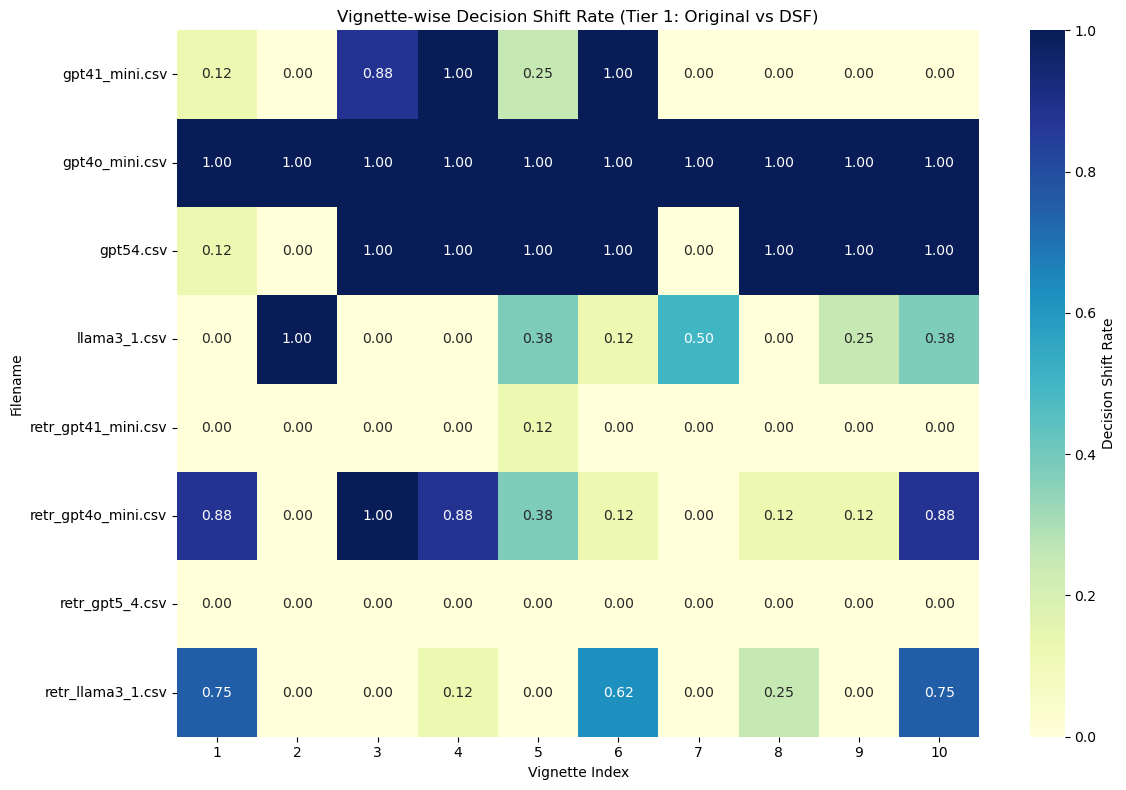

In [17]:
# Show vignette-wise decision shift rate in a heatmap format. The x-axis will be the vignette index, the y-axis will be the filename, and the color intensity will represent the decision shift rate.
import seaborn as sns
import matplotlib.pyplot as plt

def construct_heatmap_data(heatmap_data, plot_title):
    # Convert the vignette_shift_rate dictionary to a DataFrame for easier plotting
    heatmap_data_df = pd.DataFrame.from_dict(heatmap_data, orient='index', columns=['shift_rate'])
    heatmap_data_df.reset_index(inplace=True)
    heatmap_data_df[['filename', 'vignette_idx']] = pd.DataFrame(heatmap_data_df['index'].tolist(), index=heatmap_data_df.index)
    heatmap_data_df.drop('index', axis=1, inplace=True)

    heatmap_data_df['vignette_idx'] = heatmap_data_df['vignette_idx'] + 1  # Increment vignette_idx by 1 for better readability in the heatmap

    # Use keyword arguments for pivot to avoid the positional-argument error
    heatmap_data_pivot = heatmap_data_df.pivot(index='filename', columns='vignette_idx', values='shift_rate')

    # Plot the heatmap
    plt.figure(figsize=(12, 8))
    sns.heatmap(heatmap_data_pivot, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={'label': 'Decision Shift Rate'})
    plt.title(plot_title)
    plt.xlabel('Vignette Index')
    plt.ylabel('Filename')
    plt.tight_layout()
    plt.show()

# Construct heatmap for Tier 1: Original vs DSF
construct_heatmap_data(heatmap_data_tier1_dsf, 'Vignette-wise Decision Shift Rate (Tier 1: Original vs DSF)')

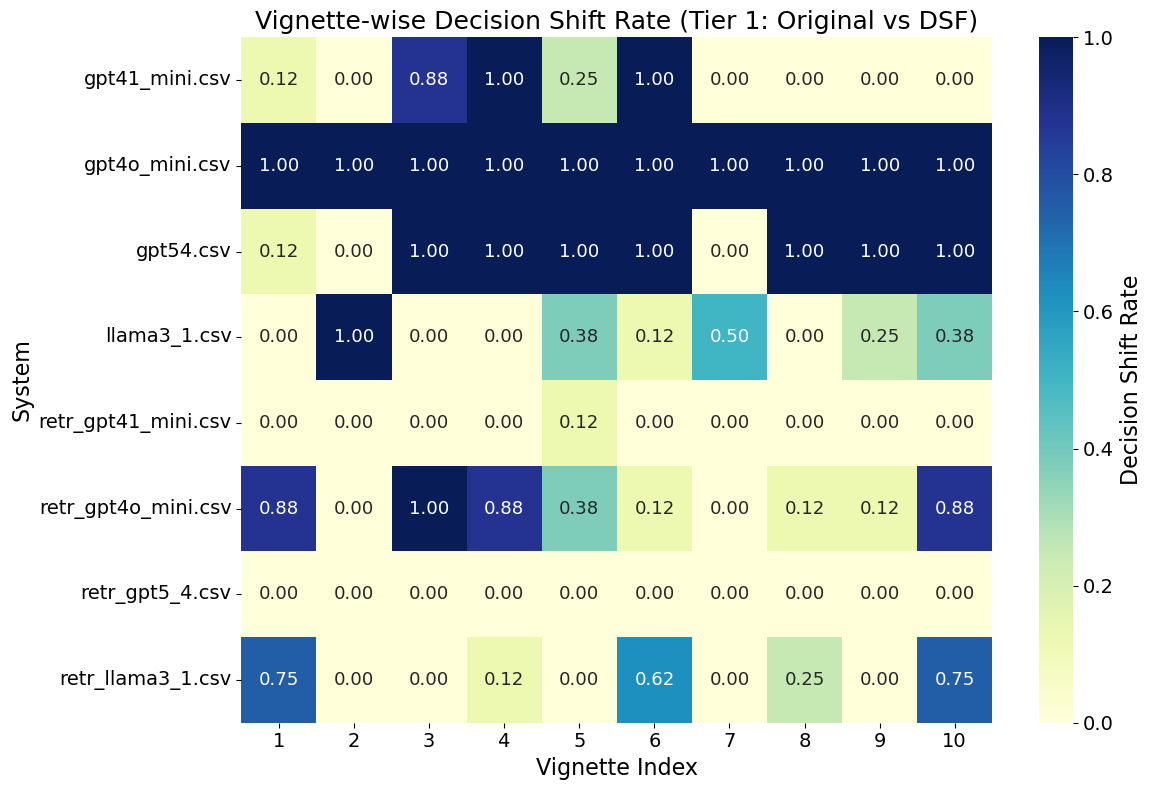

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

def construct_heatmap_data(heatmap_data, plot_title,
                           title_fs=18, label_fs=16, tick_fs=14,
                           annot_fs=13, cbar_label_fs=16, cbar_tick_fs=14):
    # Convert the vignette_shift_rate dictionary to a DataFrame for easier plotting
    heatmap_data_df = pd.DataFrame.from_dict(heatmap_data, orient='index', columns=['shift_rate'])
    heatmap_data_df.reset_index(inplace=True)
    heatmap_data_df[['filename', 'vignette_idx']] = pd.DataFrame(heatmap_data_df['index'].tolist(), index=heatmap_data_df.index)
    heatmap_data_df.drop('index', axis=1, inplace=True)

    heatmap_data_df['vignette_idx'] = heatmap_data_df['vignette_idx'] + 1  # Increment vignette_idx by 1 for better readability in the heatmap

    heatmap_data_pivot = heatmap_data_df.pivot(index='filename', columns='vignette_idx', values='shift_rate')

    # Plot the heatmap
    plt.figure(figsize=(12, 8))
    ax = sns.heatmap(
        heatmap_data_pivot,
        annot=True,
        fmt=".2f",
        cmap="YlGnBu",
        annot_kws={'size': annot_fs},              # heatmap numbers
        cbar_kws={'label': 'Decision Shift Rate'}
    )

    # Title and axis labels
    ax.set_title(plot_title, fontsize=title_fs)
    ax.set_xlabel('Vignette Index', fontsize=label_fs)
    ax.set_ylabel('System', fontsize=label_fs)

    # Axis tick labels
    ax.tick_params(axis='both', which='major', labelsize=tick_fs)

    # Colorbar (legend) label and ticks
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(labelsize=cbar_tick_fs)
    cbar.set_label('Decision Shift Rate', fontsize=cbar_label_fs)

    plt.tight_layout()
    plt.show()

# Construct heatmap for Tier 1: Original vs DSF
construct_heatmap_data(heatmap_data_tier1_dsf, 'Vignette-wise Decision Shift Rate (Tier 1: Original vs DSF)')

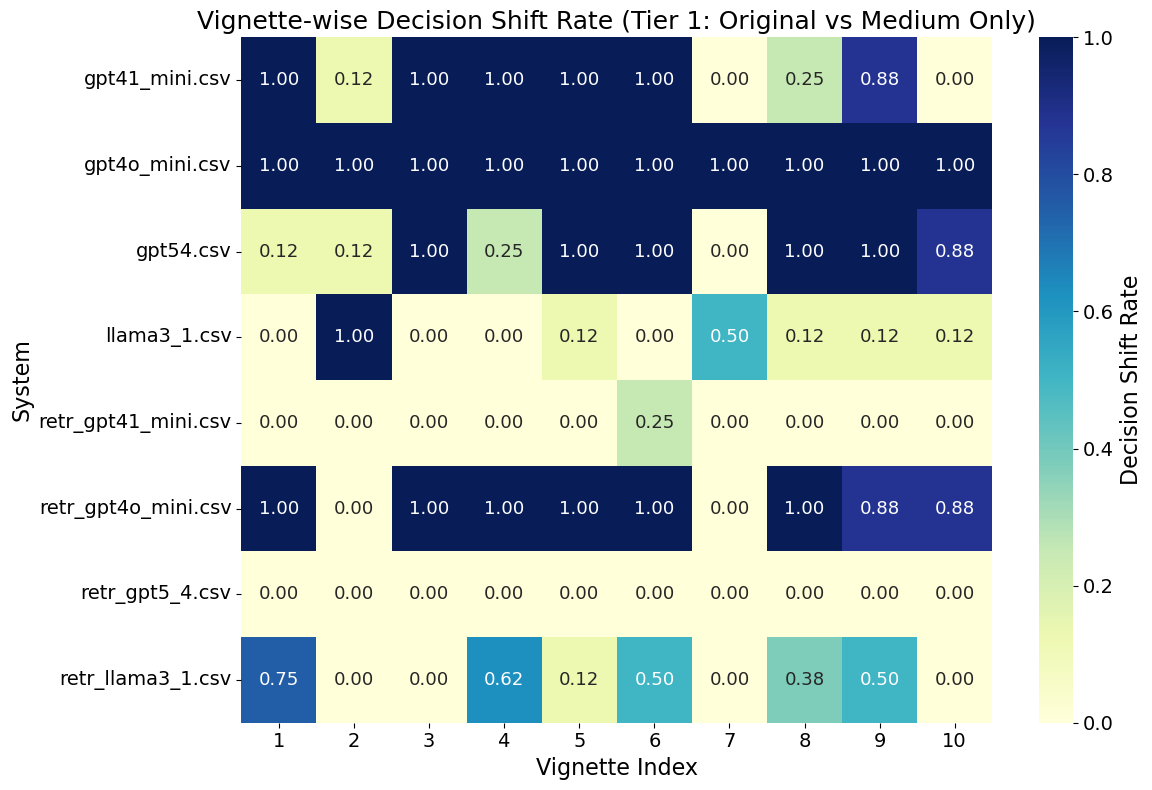

In [19]:
heatmap_data_tier1_medium_only = compute_vignette_level_decision_shift_rate(tier1_orig_dir, tier1_medium_only_dir)
# Construct heatmap for Tier 1: Original vs Medium Only
construct_heatmap_data(heatmap_data_tier1_medium_only, 'Vignette-wise Decision Shift Rate (Tier 1: Original vs Medium Only)')

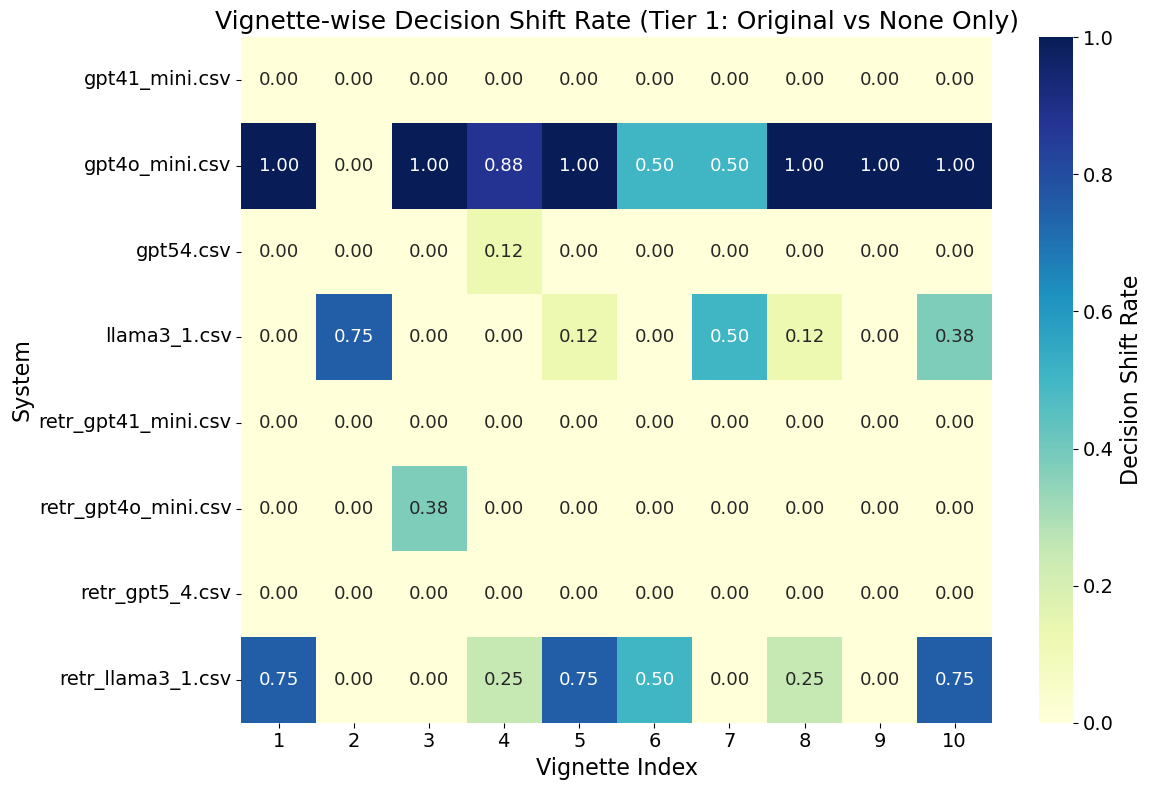

In [20]:
heatmap_data_tier1_none_only = compute_vignette_level_decision_shift_rate(tier1_orig_dir, tier1_none_only_dir)
# Construct heatmap for Tier 1: Original vs None Only
construct_heatmap_data(heatmap_data_tier1_none_only, 'Vignette-wise Decision Shift Rate (Tier 1: Original vs None Only)')

The sign-flip test asks: **if the answer options made no difference, how often would per-vignette differences this large and this consistent arise by chance?** It uses one number per vignette, so the unit of analysis is the clinical case, not the individual response.

**Procedure**

1. For each vignette $v$ and each condition, compute the share of *Low* responses per system (over its 8 demographic profiles), then average the 8 system shares so each system counts equally. This gives $\hat p_v$.
2. $\Delta_v = \hat p_v(\text{comparison}) - \hat p_v(\text{Tier 1})$. Negative means models chose *Low* less often in the comparison condition.
3. Observed statistic $T = \text{mean}(\Delta_v)$.
4. Under $H_0$ the condition labels are exchangeable within a vignette, so each $\Delta_v$ is equally likely to be $\pm$. Enumerate all $2^n$ sign assignments to get the exact null distribution of the mean.
5. Two-sided $p = \#\{|T^{*}| \ge |T|\} / 2^n$.

**Reported:** mean $\Delta_v$ with a 95% $t$-interval ($n-1$ df), the exact $p$-value, how many vignettes move in the direction of $T$, and the minimum attainable $p = 2/2^n$.

> **Note on the number of vignettes.** Set `EXCLUDED_VIGNETTES = []` to use all 10 vignettes ($2^{10}=1{,}024$, minimum $p \approx 0.002$).

In [21]:
import itertools
import numpy as np
from scipy import stats

EXCLUDED_VIGNETTES = []      # keep consistent with the analyses above; set to [] to use all vignettes
DECISION_COL = "gpt4o_dosage"


def sign_flip_test(delta):
    """Exact two-sided sign-flip (paired permutation) test on the mean of per-vignette differences."""
    delta = np.asarray(delta, float)
    n = len(delta)
    T = delta.mean()
    signs = np.array(list(itertools.product([1, -1], repeat=n)))
    null = (signs * delta).mean(axis=1)                  # 2**n means under H0
    n_extreme = int(np.sum(np.abs(null) >= abs(T) - 1e-12))
    p = n_extreme / len(null)
    sem = stats.sem(delta)
    ci = stats.t.interval(0.95, n - 1, loc=T, scale=sem) if sem > 0 else (T, T)
    return {"T": T, "ci": ci, "p": p, "n_extreme": n_extreme, "n_null": len(null),
            "p_min": 2 / len(null), "n": n, "null": null}


def low_share_by_vignette(comp_dir):
    """DataFrame (vignette x system): share of Low responses for each system on each vignette."""
    shares = {}
    for filename in sorted(os.listdir(comp_dir)):
        if not filename.endswith(".csv"):
            continue
        df = pd.read_csv(os.path.join(comp_dir, filename))
        df = df[~df["vignette_idx"].isin(EXCLUDED_VIGNETTES)]
        is_low = df[DECISION_COL].astype(str).str.contains("Low", na=False)
        shares[filename.removesuffix(".csv")] = is_low.groupby(df["vignette_idx"]).mean()
    return pd.DataFrame(shares).sort_index()


def per_vignette_delta(base_dir, comparison_dir):
    """Delta_v = p_hat_v(comparison) - p_hat_v(base), with systems weighted equally."""
    base = low_share_by_vignette(base_dir)
    comp = low_share_by_vignette(comparison_dir)
    systems = sorted(set(base.columns) & set(comp.columns))
    missing = set(base.columns) ^ set(comp.columns)
    if missing:
        print(f"Warning: systems present in only one condition were dropped: {sorted(missing)}")
    if not base.index.equals(comp.index):
        raise ValueError("Vignette indices differ between conditions.")
    if base[systems].isna().any().any() or comp[systems].isna().any().any():
        raise ValueError("Some system has no responses for some vignette.")
    p_base = base[systems].mean(axis=1)
    p_comp = comp[systems].mean(axis=1)
    return pd.DataFrame({"p_tier1": p_base, "p_comparison": p_comp, "delta": p_comp - p_base})


def report_sign_flip(base_dir, comparison_dir, label):
    tab = per_vignette_delta(base_dir, comparison_dir)
    res = sign_flip_test(tab["delta"])
    direction = np.sign(res["T"])
    n_same = int((np.sign(tab["delta"]) == direction).sum()) if direction != 0 else 0
    n_zero = int((tab["delta"] == 0).sum())
    lo, hi = res["ci"]
    print(f"=== Tier 1 vs {label} ===")
    print(tab.round(3).to_string())
    print(f"\nVignettes: {res['n']}   (null distribution: {res['n_null']:,} sign assignments)")
    print(f"Mean Δ_v = {res['T']:+.3f}   95% t-CI [{lo:+.3f}, {hi:+.3f}]  (df = {res['n'] - 1})")
    print(f"Exact two-sided p = {res['n_extreme']}/{res['n_null']:,} = {res['p']:.4f}")
    print(f"Vignettes moving in the direction of the mean: {n_same}/{res['n']}"
          + (f"  ({n_zero} with Δ_v = 0)" if n_zero else ""))
    print(f"Minimum attainable p = 2/{res['n_null']:,} = {res['p_min']:.4f}\n")
    return tab, res, n_same

In [22]:
# Primary comparison: Tier 1 vs Tier 1-DSF (Medium and None both offered)
dsf_tab, dsf_res, dsf_same = report_sign_flip(tier1_orig_dir, tier1_dsf_dir, "Tier 1-DSF")

=== Tier 1 vs Tier 1-DSF ===
              p_tier1  p_comparison  delta
vignette_idx                              
0               0.719         0.484 -0.234
1               1.000         0.750 -0.250
2               0.578         0.266 -0.312
3               0.641         0.375 -0.266
4               0.766         0.531 -0.234
5               0.812         0.422 -0.391
6               0.875         0.781 -0.094
7               0.750         0.578 -0.172
8               0.750         0.609 -0.141
9               0.750         0.422 -0.328

Vignettes: 10   (null distribution: 1,024 sign assignments)
Mean Δ_v = -0.242   95% t-CI [-0.306, -0.178]  (df = 9)
Exact two-sided p = 2/1,024 = 0.0020
Vignettes moving in the direction of the mean: 10/10
Minimum attainable p = 2/1,024 = 0.0020



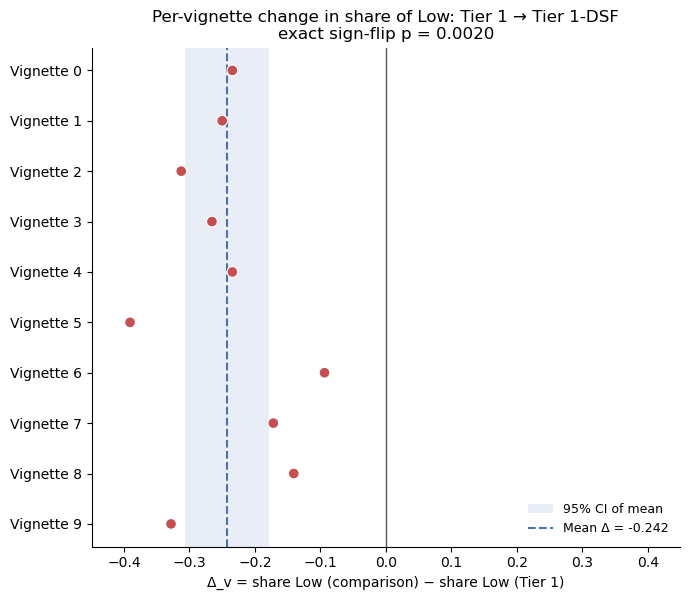

In [23]:
def plot_delta_dots(tab, res, title):
    """Dot plot of the per-vignette differences, with the mean and its 95% t-interval."""
    d = tab["delta"]
    y = np.arange(len(d))
    lo, hi = res["ci"]
    fig, ax = plt.subplots(figsize=(7, 0.45 * len(d) + 1.6))
    ax.axvspan(lo, hi, color="#4C72B0", alpha=0.12, lw=0, label="95% CI of mean")
    ax.axvline(0, color="#555555", lw=1)
    ax.axvline(res["T"], color="#4C72B0", lw=1.5, ls="--", label=f"Mean Δ = {res['T']:+.3f}")
    colors = np.where(d < 0, "#C44E52", np.where(d > 0, "#4C72B0", "#888888"))
    ax.scatter(d, y, c=colors, s=60, zorder=3, edgecolor="white", linewidth=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels([f"Vignette {v}" for v in d.index])
    ax.invert_yaxis()
    lim = max(0.05, np.abs(d).max()) * 1.15
    ax.set_xlim(-lim, lim)
    ax.set_xlabel("Δ_v = share Low (comparison) − share Low (Tier 1)")
    ax.set_title(f"{title}\nexact sign-flip p = {res['p']:.4f}")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

plot_delta_dots(dsf_tab, dsf_res, "Per-vignette change in share of Low: Tier 1 → Tier 1-DSF")

### Same test for the single-option conditions

Applying the identical procedure to *Medium only* and *None only* shows which added option drives the shift. These are three tests on the same Tier 1 baseline, so consider a multiplicity adjustment (e.g., Holm) if all three are reported as confirmatory.

In [24]:
results = {"Tier 1-DSF": (dsf_tab, dsf_res, dsf_same)}
for label, comp_dir in [("Medium only", tier1_medium_only_dir), ("None only", tier1_none_only_dir)]:
    results[label] = report_sign_flip(tier1_orig_dir, comp_dir, label)

summary = pd.DataFrame([
    {"comparison": label,
     "n_vignettes": res["n"],
     "mean_delta": res["T"],
     "ci_low": res["ci"][0],
     "ci_high": res["ci"][1],
     "p_exact": res["p"],
     "same_direction": f"{same}/{res['n']}",
     "p_min": res["p_min"]}
    for label, (tab, res, same) in results.items()
])
# Holm adjustment across the three comparisons
order = summary["p_exact"].argsort().to_numpy()
m = len(summary)
holm = np.empty(m)
running = 0.0
for rank, i in enumerate(order):
    running = max(running, min(1.0, (m - rank) * summary.loc[i, "p_exact"]))
    holm[i] = running
summary["p_holm"] = holm
summary.round(4)

=== Tier 1 vs Medium only ===
              p_tier1  p_comparison  delta
vignette_idx                              
0               0.719         0.359 -0.359
1               1.000         0.719 -0.281
2               0.578         0.250 -0.328
3               0.641         0.297 -0.344
4               0.766         0.359 -0.406
5               0.812         0.281 -0.531
6               0.875         0.750 -0.125
7               0.750         0.422 -0.328
8               0.750         0.344 -0.406
9               0.750         0.531 -0.219

Vignettes: 10   (null distribution: 1,024 sign assignments)
Mean Δ_v = -0.333   95% t-CI [-0.412, -0.254]  (df = 9)
Exact two-sided p = 2/1,024 = 0.0020
Vignettes moving in the direction of the mean: 10/10
Minimum attainable p = 2/1,024 = 0.0020

=== Tier 1 vs None only ===
              p_tier1  p_comparison  delta
vignette_idx                              
0               0.719         0.750  0.031
1               1.000         0.906 -0.094
2     

,comparison,n_vignettes,mean_delta,ci_low,ci_high,p_exact,same_direction,p_min,p_holm
0,Tier 1-DSF,10,-0.2422,-0.3063,-0.1780,0.002,10/10,0.002,0.0059
1,Medium only,10,-0.3328,-0.4119,-0.2538,0.002,10/10,0.002,0.0059
2,None only,10,0.0484,-0.0046,0.1015,0.082,8/10,0.002,0.0820


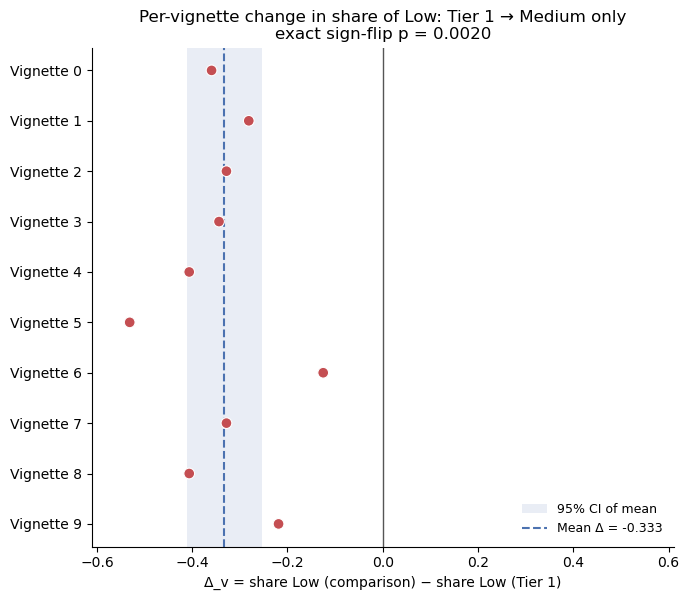

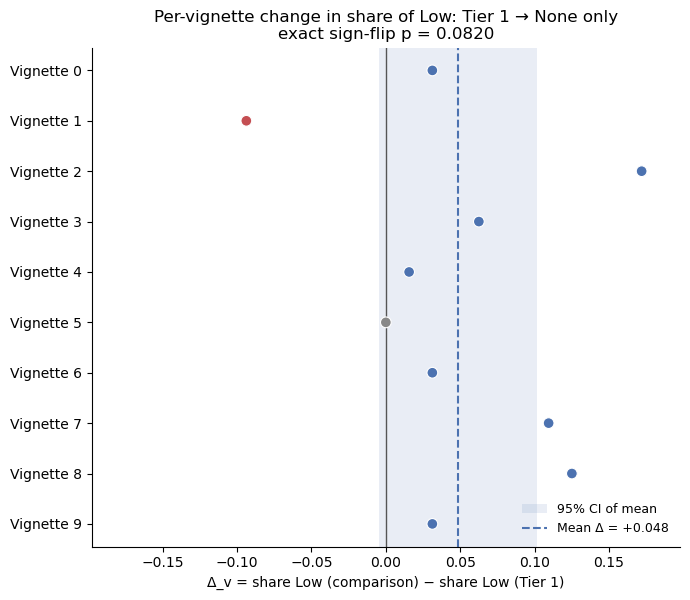

In [25]:
for label in ["Medium only", "None only"]:
    tab, res, _ = results[label]
    plot_delta_dots(tab, res, f"Per-vignette change in share of Low: Tier 1 → {label}")

## Tier-2 DSF Analysis

## Figure 2: Tier 1-DSF decision distribution by system

Replaces Figure 2 of the paper. Each bar is one system's 80 Tier 1-DSF responses, split by the option chosen. Decisions are extracted with `normalize_decision` (the same rule as the shift rates and the label audit above), so the bars agree with Table 2 and with the pooled counts in Section 4.3 (334 Low, 208 Medium, 87 High, 11 None). `Ambiguous`/`Unparsed` responses are drawn as *Unknown* and only appear in the legend if there are any.

In [26]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Filename -> display name, in the bar order of the old figure (each base model next to its retrieval variant)
FIG2_SYSTEMS = {
    "gpt4o_mini.csv":       "GPT-4o-mini",
    "retr_gpt4o_mini.csv":  "GPT-4o-mini + retr.",
    "gpt41_mini.csv":       "GPT-4.1-mini",
    "retr_gpt41_mini.csv":  "GPT-4.1-mini + retr.",
    "gpt54.csv":            "GPT-5.4",
    "retr_gpt5_4.csv":      "GPT-5.4 + retr.",
    "llama3_1.csv":         "Llama-3.1",
    "retr_llama3_1.csv":    "Llama-3.1 + retr.",
}
FIG2_CATS   = ["Medium", "Low", "High", "None", "Unknown"]          # stacking order, bottom to top
FIG2_COLORS = {"Medium": "#59A14F", "Low": "#4C78A8", "High": "#E15759",
               "None": "#B07AA1", "Unknown": "#9D9D9D"}
FIG2_OUT    = "figures/tier1_dsf_decision_distribution"            # saved as .pdf and .png
# Table 2, "DSF" column (% selecting Low) -- used only as a consistency check below
TABLE2_DSF_LOW = {"GPT-4o-mini": 0.0, "GPT-4.1-mini": 67.5, "GPT-5.4": 28.8, "Llama-3.1": 3.8,
                  "GPT-4o-mini + retr.": 56.3, "GPT-4.1-mini + retr.": 98.8,
                  "GPT-5.4 + retr.": 100.0, "Llama-3.1 + retr.": 62.5}


def decision_counts(comp_dir, systems=FIG2_SYSTEMS):
    """Counts of each option per system (rows) in one condition, using normalize_decision."""
    rows = {}
    for filename, name in systems.items():
        path = os.path.join(comp_dir, filename)
        if not os.path.exists(path):
            print(f"Missing: {path} -- skipped")
            continue
        cat = pd.read_csv(path)[DECISION_COL].map(normalize_decision)
        cat = cat.where(cat.isin(CATEGORIES), "Unknown")             # Ambiguous / Unparsed -> Unknown
        rows[name] = cat.value_counts()
    return pd.DataFrame(rows).T.reindex(columns=FIG2_CATS).fillna(0).astype(int)


fig2_counts = decision_counts(tier1_dsf_dir)
fig2_pct = 100 * fig2_counts.div(fig2_counts.sum(axis=1), axis=0)

# Consistency checks against the paper
print("Counts per system (Tier 1-DSF):")
print(fig2_counts.assign(total=fig2_counts.sum(axis=1)).to_string(), "\n")
print("Pooled:", fig2_counts.sum().to_dict(), "(paper: Low 334, Medium 208, High 87, None 11)")
check = pd.DataFrame({"figure_low_pct": fig2_pct["Low"],
                      "table2_low_pct": pd.Series(TABLE2_DSF_LOW)}).reindex(fig2_pct.index)
# Table 2 rounds half up (56.25 -> 56.3), so compare unrounded values within rounding error
check["match"] = (check["figure_low_pct"] - check["table2_low_pct"]).abs() <= 0.051
print("\nLow share vs Table 2:")
print(check.round(2).to_string())
if not check["match"].all():
    print("\nWARNING: figure and Table 2 disagree for", list(check.index[~check["match"]]))

Counts per system (Tier 1-DSF):
gpt4o_dosage          Medium  Low  High  None  Unknown  total
GPT-4o-mini               80    0     0     0        0     80
GPT-4o-mini + retr.       35   45     0     0        0     80
GPT-4.1-mini              26   54     0     0        0     80
GPT-4.1-mini + retr.       1   79     0     0        0     80
GPT-5.4                   57   23     0     0        0     80
GPT-5.4 + retr.            0   80     0     0        0     80
Llama-3.1                  5    3    62    10        0     80
Llama-3.1 + retr.          4   50    25     1        0     80 

Pooled: {'Medium': 208, 'Low': 334, 'High': 87, 'None': 11, 'Unknown': 0} (paper: Low 334, Medium 208, High 87, None 11)

Low share vs Table 2:
                      figure_low_pct  table2_low_pct  match
GPT-4o-mini                     0.00             0.0   True
GPT-4o-mini + retr.            56.25            56.3   True
GPT-4.1-mini                   67.50            67.5   True
GPT-4.1-mini + retr.    

Saved figures/tier1_dsf_decision_distribution.pdf and .png


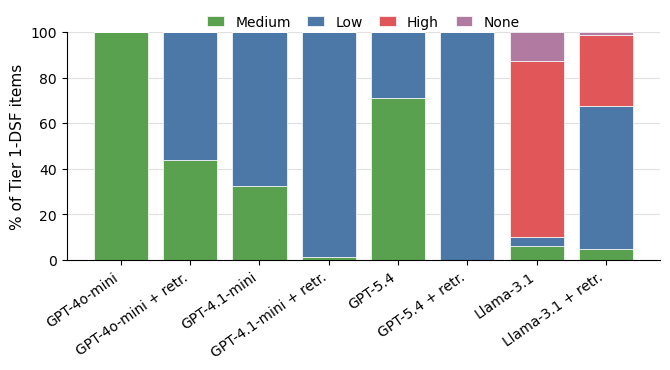

In [27]:
def plot_decision_distribution(pct, save_stem=None, ylabel="% of Tier 1-DSF items"):
    cats = [c for c in FIG2_CATS if pct[c].sum() > 0]               # drop empty categories (e.g. Unknown)
    x = np.arange(len(pct))
    fig, ax = plt.subplots(figsize=(6.8, 3.9))
    bottom = np.zeros(len(pct))
    for c in cats:
        ax.bar(x, pct[c].to_numpy(), bottom=bottom, width=0.78, label=c,
               color=FIG2_COLORS[c], edgecolor="white", linewidth=0.5, zorder=2)
        bottom += pct[c].to_numpy()
    ax.set_xticks(x)
    ax.set_xticklabels(pct.index, rotation=35, ha="right", fontsize=10)
    ax.set_ylabel(ylabel, fontsize=11)
    ax.set_ylim(0, 100)
    ax.set_yticks(range(0, 101, 20))
    ax.tick_params(axis="y", labelsize=10)
    ax.grid(axis="y", color="0.88", zorder=0)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, 1.13), ncol=len(cats),
              frameon=False, fontsize=10, handlelength=1.2, columnspacing=1.2)
    fig.tight_layout()
    if save_stem:
        os.makedirs(os.path.dirname(save_stem) or ".", exist_ok=True)
        fig.savefig(save_stem + ".pdf", bbox_inches="tight")
        fig.savefig(save_stem + ".png", dpi=300, bbox_inches="tight")
        print(f"Saved {save_stem}.pdf and .png")
    plt.show()


plot_decision_distribution(fig2_pct, FIG2_OUT)

## Tier 1-N decision distribution by system

The same stacked plot for **Tier 1-N** (Low, High and None offered; no Medium). It reuses `decision_counts` and `plot_decision_distribution` from the Figure 2 cells above, so run those first. Medium is never offered here, so it drops out of the legend. The check compares against Table 2's **N** column and the label audit's pooled counts (520 Low, 116 High, 4 None).

Counts per system (Tier 1-N):
gpt4o_dosage          Medium  Low  High  None  Unknown  total
GPT-4o-mini                0   79     1     0        0     80
GPT-4o-mini + retr.        0   80     0     0        0     80
GPT-4.1-mini               0   80     0     0        0     80
GPT-4.1-mini + retr.       0   80     0     0        0     80
GPT-5.4                    0   72     8     0        0     80
GPT-5.4 + retr.            0   80     0     0        0     80
Llama-3.1                  0    5    72     3        0     80
Llama-3.1 + retr.          0   44    35     1        0     80 

Pooled: {'Medium': 0, 'Low': 520, 'High': 116, 'None': 4, 'Unknown': 0} (label audit: Low 520, High 116, None 4)

Low share vs Table 2 (N column):
                      figure_low_pct  table2_low_pct  match
GPT-4o-mini                    98.75            98.8   True
GPT-4o-mini + retr.           100.00           100.0   True
GPT-4.1-mini                  100.00           100.0   True
GPT-4.1-mini + retr.   

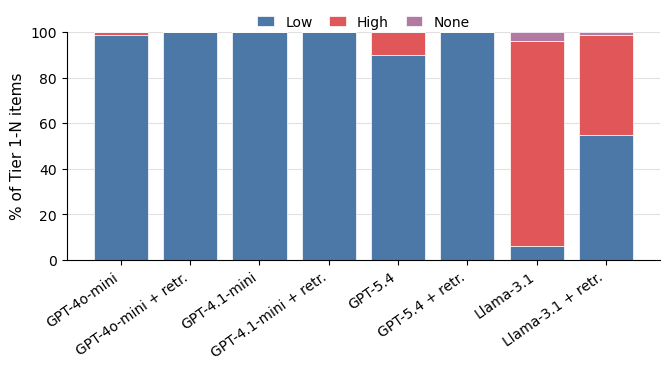

In [28]:
FIGN_OUT = "figures/tier1_none_only_decision_distribution"         # saved as .pdf and .png
# Table 2, "N" column (% selecting Low) -- used only as a consistency check below
TABLE2_N_LOW = {"GPT-4o-mini": 98.8, "GPT-4.1-mini": 100.0, "GPT-5.4": 90.0, "Llama-3.1": 6.3,
                "GPT-4o-mini + retr.": 100.0, "GPT-4.1-mini + retr.": 100.0,
                "GPT-5.4 + retr.": 100.0, "Llama-3.1 + retr.": 55.0}

figN_counts = decision_counts(tier1_none_only_dir)
figN_pct = 100 * figN_counts.div(figN_counts.sum(axis=1), axis=0)

print("Counts per system (Tier 1-N):")
print(figN_counts.assign(total=figN_counts.sum(axis=1)).to_string(), "\n")
print("Pooled:", figN_counts.sum().to_dict(), "(label audit: Low 520, High 116, None 4)")
checkN = pd.DataFrame({"figure_low_pct": figN_pct["Low"],
                       "table2_low_pct": pd.Series(TABLE2_N_LOW)}).reindex(figN_pct.index)
# Table 2 rounds half up, so compare unrounded values within rounding error
checkN["match"] = (checkN["figure_low_pct"] - checkN["table2_low_pct"]).abs() <= 0.051
print("\nLow share vs Table 2 (N column):")
print(checkN.round(2).to_string())
if not checkN["match"].all():
    print("\nWARNING: figure and Table 2 disagree for", list(checkN.index[~checkN["match"]]))

plot_decision_distribution(figN_pct, FIGN_OUT, ylabel="% of Tier 1-N items")

## Extending to ordering of retrieved evidence

In [29]:
tier1_retr_original_dir= "../experiment_results/tier1_retr_chunk_original_order/"
tier1_retr_reverse_dir= "../experiment_results/tier1_retr_chunk_reverse_order/"
tier1_retr_random_dir= "../experiment_results/tier1_retr_chunk_random_order/"

In [30]:
print(compute_decision_shift_rate(tier1_retr_original_dir, tier1_retr_random_dir))

Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama31.csv...
{'retr_gpt41_mini.csv': 0.0, 'retr_gpt4o_mini.csv': 0.075, 'retr_gpt5_4.csv': 0.0, 'retr_llama31.csv': 0.075}


In [31]:
print(compute_decision_shift_rate(tier1_retr_original_dir, tier1_retr_reverse_dir))

Processing retr_gpt41_mini.csv...
Processing retr_gpt4o_mini.csv...
Processing retr_gpt5_4.csv...
Processing retr_llama31.csv...
{'retr_gpt41_mini.csv': 0.0, 'retr_gpt4o_mini.csv': 0.05, 'retr_gpt5_4.csv': 0.0, 'retr_llama31.csv': 0.05}


In [32]:
print(compute_accuracy(tier1_retr_original_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'retr_llama31.csv': np.float64(0.875), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(0.9625)}


In [33]:
print(compute_accuracy(tier1_retr_reverse_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'retr_llama31.csv': np.float64(0.825), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(0.9125)}


In [34]:
print(compute_accuracy(tier1_retr_random_dir))

{'retr_gpt5_4.csv': np.float64(1.0), 'retr_llama31.csv': np.float64(0.8), 'retr_gpt41_mini.csv': np.float64(1.0), 'retr_gpt4o_mini.csv': np.float64(0.9625)}


## Q-Pain bias audit: does the decision-space framing change it?

This section re-runs the bias audit of the Q-Pain paper (Logé et al., NeurIPS 2021 Datasets & Benchmarks, §3.3 and §4.2) on every system in each Tier 1 condition, then asks whether changing the answer options (decision-space framing, DSF) changes what the audit concludes.

**The paper's audit, and how it maps onto these results**

| Q-Pain paper | Here |
|---|---|
| Outcome: probability of "No" (treatment denied), from GPT-3 token probabilities | **`denial`**: share of responses whose treatment answer (`gpt4o_answer`) is *No*. Falls back to dosage = *None* if a folder has no answer column. |
| Secondary outcome: probability of a "Low" dose | **`low`**: share of responses choosing *Low*, over all parsed responses |
| (not in the paper: only Low/High were offered) | **`supply_weeks`**: supply prescribed, None = 0, Low = 1, Medium = 2, High = 4 weeks. Captures moves to Medium that `low` cannot tell apart from moves to High. |
| 8 race × gender subgroups (Asian, Black, Hispanic, White × woman, man) | the same 8, read from the race and gender columns of each CSV |
| 28 subgroup-vs-subgroup comparisons, paired two-tailed t-test over vignettes | the same: per vignette, the subgroup's rate over its responses; paired t-test across the 10 vignettes |
| 95% CI and Bonferroni-corrected CI (99.8%, i.e. α = 0.05/28) | the same. Race-only (6 pairs) and gender-only (1 pair) families are corrected within their own family |
| *A v B* > 0 means A is at a disadvantage | the same. For `supply_weeks` the sign is flipped, so > 0 still means A gets **less** |

Our systems are prompted for a decision rather than scored by token probabilities, so each rate is a share of discrete responses. The paper used probabilities. In Tier 1 each vignette is answered once per subgroup (80 responses = 10 vignettes × 8 subgroups), so a subgroup's per-vignette rate is 0 or 1 and each per-vignette gap is −1, 0 or +1.

**What the DSF question adds.** The same prompts are answered under each option set, so each vignette contributes a gap under the original options and a gap under DSF. For each of the 28 comparisons and each system we report:

1. **Verdict change.** The paper-style verdict (Bonferroni CI excludes 0) under Tier 1 and under each alternative option set: *stable n.s.*, *stable significant*, *emerges*, *disappears*, or *reverses*.
2. **Difference-in-differences (DiD).** Per vignette, gap(alternative) − gap(Tier 1), with a paired t-test and Bonferroni CI. A significant DiD means the framing itself moves the disparity, which is a stronger claim than a verdict that flips around the threshold.
3. **Omnibus tests (permutation).** Per condition: do the 8 subgroups differ at all? Statistic: variance of the 8 subgroup means. Null: subgroup labels shuffled within each vignette (and within each replicate block of a vignette). **Interaction**: the same test on the per-response change score y(alternative) − y(Tier 1). This asks whether the framing affects some subgroups more than others, as one test per system instead of 28.

Run the cells above first. This section reuses `normalize_decision`, `CATEGORIES`, `DECISION_COL`, `ALIGN_KEYS` and the folder variables.

In [35]:
# ---------------------------------------------------------------------------------------------
# Q-Pain bias audit: configuration (Tier 1)
# ---------------------------------------------------------------------------------------------
import itertools
import os
import re
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

# Condition label -> results folder. The FIRST entry is the baseline every other condition is compared with.
QP_CONDITIONS = {
    "Tier 1":     tier1_orig_dir,
    "Tier 1-DSF": tier1_dsf_dir,            # Medium and None both offered
    "Tier 1-M":   tier1_medium_only_dir,    # Medium only
    "Tier 1-N":   tier1_none_only_dir,      # None only
}
QP_BASE = next(iter(QP_CONDITIONS))

# CSV file stem -> display name (each base model next to its retrieval variant, as in the paper figures)
QP_SYSTEMS = {
    "gpt4o_mini": "GPT-4o-mini",   "retr_gpt4o_mini": "GPT-4o-mini + retr.",
    "gpt41_mini": "GPT-4.1-mini",  "retr_gpt41_mini": "GPT-4.1-mini + retr.",
    "gpt54":      "GPT-5.4",       "retr_gpt5_4":     "GPT-5.4 + retr.",
    "llama3_1":   "Llama-3.1",     "retr_llama3_1":   "Llama-3.1 + retr.",
}

# Subgroups in the order of the Q-Pain paper's figures (women first)
QP_RACES = ["Asian", "Black", "Hispanic", "White"]
QP_GENDERS = ["woman", "man"]
QP_SUBGROUPS = [f"{r} {g}" for g in QP_GENDERS for r in QP_RACES]

# Column names. None = auto-detect (a column whose name contains "race" / "gender" or "sex").
QP_RACE_COL = None
QP_GENDER_COL = None
QP_ANSWER_COL = "gpt4o_answer"           # Yes/No treatment decision; if missing, denial = dosage "None"

# Outcomes. harm_sign makes every reported gap "positive = Group A at a disadvantage" (paper convention).
QP_SUPPLY_WEEKS = {"None": 0.0, "Low": 1.0, "Medium": 2.0, "High": 4.0}
QP_OUTCOMES = {
    "denial":       {"label": 'Denial: share answering "No"',    "harm_sign": +1, "scale": 100, "unit": "pp"},
    "low":          {"label": 'Low dose: share choosing "Low"',   "harm_sign": +1, "scale": 100, "unit": "pp"},
    "supply_weeks": {"label": "Supply prescribed (weeks)",        "harm_sign": -1, "scale": 1,   "unit": "wk"},
}

QP_UNIT_KEYS = ["vignette_idx"]          # unit of pairing for the t-tests: the vignette, as in the paper
QP_ALPHA = 0.05
QP_N_PERM = 10_000                       # permutations for the omnibus / interaction tests
QP_SEED = 20211206
QP_OUT_DIR = "../results/qpain_bias_audit/tier1/"               # tables (.csv) and figures (.pdf/.png)
QP_STYLE = {"font.family": "sans-serif", "font.size": 9, "axes.edgecolor": "black", "axes.linewidth": 0.8,
            "xtick.color": "black", "ytick.color": "black"}   # local style; the global rcParams are left alone

os.makedirs(QP_OUT_DIR, exist_ok=True)
for _label, _folder in QP_CONDITIONS.items():
    if not os.path.isdir(_folder):
        print(f"Missing folder for {_label}: {_folder}")

In [36]:
# ---------------------------------------------------------------------------------------------
# Load every condition, derive the three outcomes, and pair the same prompt across conditions
# ---------------------------------------------------------------------------------------------
_QP_GENDER_MAP = {"man": "man", "men": "man", "male": "man", "m": "man",
                  "woman": "woman", "women": "woman", "female": "woman", "f": "woman", "w": "woman"}
_QP_ANS_RE = re.compile(r"\b(yes|no)\b", re.IGNORECASE)
_QP_SENT_END = re.compile(r"[.;\n]")


def qp_normalize_answer(x):
    """'Yes' / 'No' from a raw treatment answer; the first sentence decides; otherwise NaN."""
    if pd.isna(x):
        return np.nan
    s = str(x).strip()
    for text in (_QP_SENT_END.split(s, maxsplit=1)[0], s):
        hits = {h.capitalize() for h in _QP_ANS_RE.findall(text)}
        if len(hits) == 1:
            return hits.pop()
        if len(hits) > 1:
            return np.nan
    return np.nan


def _qp_find_col(df, override, keys, what):
    if override:
        return override
    exact = [c for c in df.columns if c.lower() in keys]
    hits = exact or [c for c in df.columns if any(k in c.lower() for k in keys)]
    if len(hits) != 1:
        raise KeyError(f"Cannot identify the {what} column (candidates: {hits}); columns are {list(df.columns)}. "
                       f"Set QP_{what.upper()}_COL by hand.")
    return hits[0]


def qp_load(folder, stem):
    """One row per response: alignment keys, race, gender and the three outcomes (NaN if unparsed)."""
    path = os.path.join(folder, stem + ".csv")
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    race_col = _qp_find_col(df, QP_RACE_COL, ["race"], "race")
    gender_col = _qp_find_col(df, QP_GENDER_COL, ["gender", "sex"], "gender")
    out = df[ALIGN_KEYS].copy()
    out["_ord"] = out.groupby(ALIGN_KEYS).cumcount()
    out["race"] = df[race_col].astype(str).str.strip().str.title()
    out["gender"] = df[gender_col].astype(str).str.strip().str.lower().map(_QP_GENDER_MAP)
    bad = ~out["race"].isin(QP_RACES) | out["gender"].isna()
    if bad.any():
        raise ValueError(f"{path}: unrecognised race/gender values, e.g. "
                         f"{df.loc[bad, [race_col, gender_col]].drop_duplicates().head().values.tolist()}")
    dosage = df[DECISION_COL].map(normalize_decision)
    parsed = dosage.isin(CATEGORIES)
    out["low"] = np.where(parsed, (dosage == "Low").astype(float), np.nan)
    out["supply_weeks"] = dosage.map(QP_SUPPLY_WEEKS).astype(float)
    if QP_ANSWER_COL in df.columns:
        out["denial"] = df[QP_ANSWER_COL].map(qp_normalize_answer).map({"No": 1.0, "Yes": 0.0}).astype(float)
    else:
        out["denial"] = np.where(parsed, (dosage == "None").astype(float), np.nan)
    return out


def qp_build_wide(stem):
    """One row per prompt; outcome columns are named '<outcome>|<condition>'. Rows are matched across
    conditions on ALIGN_KEYS + order within them (as in the shift-rate analysis), and every matched row
    must carry the same race and gender."""
    keys = ALIGN_KEYS + ["_ord"]
    wide = None
    for cond, folder in QP_CONDITIONS.items():
        d = qp_load(folder, stem)
        if d is None:
            print(f"  {stem}: no file in {cond} ({folder}); system skipped")
            return None
        d = d.set_index(keys).sort_index()
        if wide is None:
            wide = d[["race", "gender"]].copy()
        else:
            if not d.index.equals(wide.index):
                raise ValueError(f"{stem}: {cond} does not have the same prompts as {QP_BASE}")
            mism = ((d["race"] != wide["race"]) | (d["gender"] != wide["gender"])).sum()
            if mism:
                raise ValueError(f"{stem}: {mism} rows of {cond} have different demographics from {QP_BASE}; "
                                 f"add the profile / risk-factor columns to ALIGN_KEYS.")
        for o in QP_OUTCOMES:
            wide[f"{o}|{cond}"] = d[o]
    wide = wide.reset_index()
    wide["subgroup"] = wide["race"] + " " + wide["gender"]
    # replicate index: k-th response of this subgroup within the vignette (Tier 2: one per risk-factor variant)
    wide["rep"] = wide.sort_values(keys).groupby(QP_UNIT_KEYS + ["subgroup"]).cumcount()
    return wide


QP_DATA = {}
for stem in QP_SYSTEMS:
    w = qp_build_wide(stem)
    if w is not None:
        QP_DATA[stem] = w

# Design check: the audit assumes every vignette shows every subgroup equally often
design = []
for stem, w in QP_DATA.items():
    cell = w.groupby(QP_UNIT_KEYS + ["subgroup"]).size()
    n_missing = {c: int(w[[f"{o}|{c}" for o in QP_OUTCOMES]].isna().any(axis=1).sum()) for c in QP_CONDITIONS}
    design.append({"system": QP_SYSTEMS[stem], "responses": len(w), "units": w.groupby(QP_UNIT_KEYS).ngroups,
                   "subgroups": w["subgroup"].nunique(),
                   "per subgroup per unit": f"{cell.min()}" if cell.min() == cell.max() else f"{cell.min()}-{cell.max()} (UNBALANCED)",
                   "rows with an unparsed outcome": n_missing})
print(f"Conditions: {list(QP_CONDITIONS)} (baseline: {QP_BASE})")
pd.DataFrame(design).set_index("system")

Conditions: ['Tier 1', 'Tier 1-DSF', 'Tier 1-M', 'Tier 1-N'] (baseline: Tier 1)


,responses,units,subgroups,per subgroup per unit,rows with an unparsed outcome
system,,,,,
GPT-4o-mini,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
GPT-4o-mini + retr.,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
GPT-4.1-mini,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
GPT-4.1-mini + retr.,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
GPT-5.4,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
GPT-5.4 + retr.,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
Llama-3.1,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."
Llama-3.1 + retr.,80,10,8,1,"{'Tier 1': 0, 'Tier 1-DSF': 0, 'Tier 1-M': 0, ..."


In [37]:
# ---------------------------------------------------------------------------------------------
# Statistics: the paper's paired t-test with 95% / Bonferroni CIs, DiD, and permutation omnibus tests
# ---------------------------------------------------------------------------------------------
QP_FAMILIES = {"race x gender": ("subgroup", QP_SUBGROUPS),   # 28 comparisons, as in the paper
               "race":          ("race", QP_RACES),           # 6
               "gender":        ("gender", QP_GENDERS)}       # 1


def qp_unit_table(w, col, group_col, levels):
    """Units (vignettes) x groups: mean outcome of each group in each vignette."""
    return w.pivot_table(index=QP_UNIT_KEYS, columns=group_col, values=col, aggfunc="mean").reindex(columns=levels)


def qp_sign_flip_p(x, rng):
    """Two-sided sign-flip p for the mean of paired differences (exact up to 16 units, else Monte Carlo)."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    if len(x) == 0:
        return np.nan
    if np.allclose(x, 0):
        return 1.0
    T = abs(x.mean())
    if len(x) <= 16:
        null = np.abs((np.array(list(itertools.product([1, -1], repeat=len(x)))) * x).mean(axis=1))
        return float(np.mean(null >= T - 1e-12))
    null = np.abs((rng.choice([1, -1], size=(QP_N_PERM, len(x))) * x).mean(axis=1))
    return float((1 + np.sum(null >= T - 1e-12)) / (1 + QP_N_PERM))


def qp_paired_t(x, m):
    """Paired two-tailed t-test on per-unit differences x, with 95% and Bonferroni (alpha/m) CIs.
    Zero variance: p = 1 if every difference is 0 ('no variation'), p = 0 if all equal a non-zero value."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    n = len(x)
    r = {"n_units": n, "gap": x.mean() if n else np.nan, "t": np.nan, "p": np.nan,
         "ci95_lo": np.nan, "ci95_hi": np.nan, "ciB_lo": np.nan, "ciB_hi": np.nan, "note": ""}
    if n < 2:
        r["note"] = "too few units"
        return r
    sd = x.std(ddof=1)
    if sd == 0:
        r.update(p=1.0 if r["gap"] == 0 else 0.0, ci95_lo=r["gap"], ci95_hi=r["gap"], ciB_lo=r["gap"], ciB_hi=r["gap"],
                 note="no variation" if r["gap"] == 0 else "constant gap")
        return r
    se = sd / np.sqrt(n)
    r["t"] = r["gap"] / se
    r["p"] = 2 * stats.t.sf(abs(r["t"]), n - 1)
    h95 = stats.t.ppf(1 - QP_ALPHA / 2, n - 1) * se
    hB = stats.t.ppf(1 - QP_ALPHA / (2 * m), n - 1) * se
    r.update(ci95_lo=r["gap"] - h95, ci95_hi=r["gap"] + h95, ciB_lo=r["gap"] - hB, ciB_hi=r["gap"] + hB)
    return r


def qp_verdict(lo, hi):
    if lo > 0:
        return "A disadvantaged"
    if hi < 0:
        return "B disadvantaged"
    return "n.s."


def qp_pairwise(w, value_cols, outcome, family, rng):
    """All pairwise comparisons in a family. value_cols = [col] for one condition, or [comp_col, base_col]
    for the difference-in-differences gap(comp) - gap(base). Gaps are harm-oriented (> 0: A disadvantaged)."""
    group_col, levels = QP_FAMILIES[family]
    sign = QP_OUTCOMES[outcome]["harm_sign"]
    tabs = [qp_unit_table(w, c, group_col, levels) for c in value_cols]
    pairs = list(itertools.combinations(levels, 2))
    rows = []
    for A, B in pairs:
        gaps = [sign * (t[A] - t[B]) for t in tabs]
        x = (gaps[0] - gaps[1]) if len(gaps) == 2 else gaps[0]
        r = qp_paired_t(x.to_numpy(), len(pairs))
        r.update(A=A, B=B, p_signflip=qp_sign_flip_p(x.to_numpy(), rng))
        if len(tabs) == 1:
            r.update(rate_A=tabs[0][A].mean(), rate_B=tabs[0][B].mean())
        rows.append(r)
    df = pd.DataFrame(rows)
    df["p_bonf"] = np.minimum(1.0, df["p"] * len(pairs))
    df["verdict_95"] = [qp_verdict(lo, hi) for lo, hi in zip(df["ci95_lo"], df["ci95_hi"])]
    df["verdict_bonf"] = [qp_verdict(lo, hi) for lo, hi in zip(df["ciB_lo"], df["ciB_hi"])]
    return df


def qp_perm_index(w, rng):
    """QP_N_PERM x n matrix: row i of a permuted data set takes its group label from row idx[i], where
    labels are shuffled only within blocks (vignette x replicate), so vignette effects are held fixed."""
    block = w.groupby(list(dict.fromkeys(QP_UNIT_KEYS + ["rep"]))).ngroup().to_numpy()
    n = len(block)
    base = np.lexsort((np.arange(n), block))
    idx = np.empty((QP_N_PERM, n), dtype=np.int32)
    for p in range(QP_N_PERM):
        order = np.lexsort((rng.random(n), block))
        idx[p, base] = order
    return idx


def qp_between_var(y, codes, G, idx=None, chunk=1000):
    """Variance of the G group means of y (NaN ignored); for every permutation in idx if given."""
    ok = np.isfinite(y)
    y0, wt = np.where(ok, y, 0.0), ok.astype(float)
    if idx is None:
        idx = np.arange(len(y))[None, :]
    out = []
    for s in range(0, len(idx), chunk):
        L = codes[idx[s:s + chunk]]
        P = len(L)
        flat = (np.arange(P)[:, None] * G + L).ravel()
        sums = np.bincount(flat, weights=np.tile(y0, P), minlength=P * G).reshape(P, G)
        cnts = np.bincount(flat, weights=np.tile(wt, P), minlength=P * G).reshape(P, G)
        with np.errstate(invalid="ignore", divide="ignore"):
            out.append(np.nanvar(sums / cnts, axis=1))
    return np.concatenate(out)


def qp_perm_test(y, codes, G, idx):
    obs = qp_between_var(y, codes, G)[0]
    if not np.isfinite(obs) or obs < 1e-15:
        return obs, 1.0
    null = qp_between_var(y, codes, G, idx)
    return obs, float((1 + np.sum(null >= obs * (1 - 1e-9))) / (1 + len(null)))

In [38]:
# ---------------------------------------------------------------------------------------------
# Run the audit for every system x outcome x condition (and every condition against the baseline)
# ---------------------------------------------------------------------------------------------
rng = np.random.default_rng(QP_SEED)
_rates, _pairs, _did, _omni = [], [], [], []
QP_COMPARISONS = [c for c in QP_CONDITIONS if c != QP_BASE]

for stem, w in QP_DATA.items():
    system = QP_SYSTEMS[stem]
    idx = qp_perm_index(w, rng)
    codes = {fam: pd.Categorical(w[col], categories=lv).codes for fam, (col, lv) in QP_FAMILIES.items()}
    for o in QP_OUTCOMES:
        for cond in QP_CONDITIONS:
            col = f"{o}|{cond}"
            # subgroup rates (paper Fig. 2a): mean over vignettes of each subgroup's per-vignette rate
            for fam, (gcol, levels) in QP_FAMILIES.items():
                t = qp_unit_table(w, col, gcol, levels)
                for g in levels:
                    _rates.append({"system": system, "outcome": o, "condition": cond, "family": fam,
                                   "group": g, "rate": t[g].mean()})
            _rates.append({"system": system, "outcome": o, "condition": cond, "family": "all",
                           "group": "All patients", "rate": qp_unit_table(w, col, "gender", QP_GENDERS).mean(axis=1).mean()})
            for fam in QP_FAMILIES:
                _pairs.append(qp_pairwise(w, [col], o, fam, rng).assign(system=system, outcome=o, condition=cond, family=fam))
                stat, p = qp_perm_test(w[col].to_numpy(float), codes[fam], len(QP_FAMILIES[fam][1]), idx)
                _omni.append({"system": system, "outcome": o, "test": "bias", "condition": cond, "family": fam,
                              "stat": stat, "p_perm": p})
        for comp in QP_COMPARISONS:
            cb, cc = f"{o}|{QP_BASE}", f"{o}|{comp}"
            for fam in QP_FAMILIES:
                _did.append(qp_pairwise(w, [cc, cb], o, fam, rng).assign(system=system, outcome=o, comparison=comp, family=fam))
                change = (w[cc] - w[cb]).to_numpy(float)
                stat, p = qp_perm_test(change, codes[fam], len(QP_FAMILIES[fam][1]), idx)
                _omni.append({"system": system, "outcome": o, "test": "interaction", "condition": comp, "family": fam,
                              "stat": stat, "p_perm": p})
    print(f"done: {system}")

QP_RATES = pd.DataFrame(_rates)
QP_PAIRS = pd.concat(_pairs, ignore_index=True)
QP_DID = pd.concat(_did, ignore_index=True)
QP_OMNI = pd.DataFrame(_omni)

# Verdict transitions (paper's Bonferroni CI) from the baseline to each alternative option set
_b = QP_PAIRS[QP_PAIRS["condition"] == QP_BASE].set_index(["system", "outcome", "family", "A", "B"])
_TRANS = {(False, False): "stable n.s.", (True, True): "stable significant",
          (False, True): "emerges", (True, False): "disappears"}
for k in ["gap", "verdict_bonf", "verdict_95", "ciB_lo", "ciB_hi"]:
    QP_DID[f"{k}_base"] = QP_DID.set_index(["system", "outcome", "family", "A", "B"]).index.map(_b[k])
_c = QP_PAIRS.set_index(["system", "outcome", "condition", "family", "A", "B"])
for k in ["gap", "verdict_bonf", "verdict_95", "ciB_lo", "ciB_hi"]:
    QP_DID[f"{k}_comp"] = QP_DID.set_index(["system", "outcome", "comparison", "family", "A", "B"]).index.map(_c[k])


def _transition(vb, vc):
    if vb != "n.s." and vc != "n.s." and vb != vc:
        return "reverses"
    return _TRANS[(vb != "n.s.", vc != "n.s.")]


QP_DID["transition"] = [_transition(a, b) for a, b in zip(QP_DID["verdict_bonf_base"], QP_DID["verdict_bonf_comp"])]
QP_DID = QP_DID.rename(columns={"gap": "did", "t": "did_t", "p": "did_p", "p_bonf": "did_p_bonf",
                                "p_signflip": "did_p_signflip", "ci95_lo": "did_ci95_lo", "ci95_hi": "did_ci95_hi",
                                "ciB_lo": "did_ciB_lo", "ciB_hi": "did_ciB_hi", "verdict_95": "did_verdict_95",
                                "verdict_bonf": "did_verdict_bonf"})
print(f"\n{len(QP_PAIRS):,} pairwise tests, {len(QP_DID):,} DiD tests, {len(QP_OMNI):,} permutation tests "
      f"({QP_N_PERM:,} permutations each)")

done: GPT-4o-mini
done: GPT-4o-mini + retr.
done: GPT-4.1-mini
done: GPT-4.1-mini + retr.
done: GPT-5.4
done: GPT-5.4 + retr.
done: Llama-3.1
done: Llama-3.1 + retr.

3,360 pairwise tests, 2,520 DiD tests, 504 permutation tests (10,000 permutations each)


### Headline: does the framing change the audit?

One row per system and outcome, for the 28 race × gender comparisons (the paper's main analysis):

* **bias p**: omnibus permutation p that the 8 subgroups differ at all, under each option set.
* **sig. pairs**: comparisons whose Bonferroni CI excludes 0 (the paper's criterion), out of 28.
* **max gap**: largest disparity between any two subgroups (pp, or weeks for supply).
* **interaction p**: permutation p that the framing shifts some subgroups more than others.
* **DiD sig.**: comparisons whose gap changes significantly (Bonferroni) between option sets.
* **transitions**: how many of the 28 verdicts emerge, disappear or reverse.

In [39]:
def qp_headline(comp, family="race x gender"):
    rows = []
    for stem in QP_DATA:
        system = QP_SYSTEMS[stem]
        for o, meta in QP_OUTCOMES.items():
            def omni(test, cond):
                q = QP_OMNI[(QP_OMNI["system"] == system) & (QP_OMNI["outcome"] == o) & (QP_OMNI["test"] == test)
                            & (QP_OMNI["condition"] == cond) & (QP_OMNI["family"] == family)]
                return q["p_perm"].iloc[0]
            pb = QP_PAIRS.query("system == @system and outcome == @o and condition == @QP_BASE and family == @family")
            pc = QP_PAIRS.query("system == @system and outcome == @o and condition == @comp and family == @family")
            d = QP_DID.query("system == @system and outcome == @o and comparison == @comp and family == @family")
            tr = d["transition"].value_counts()
            rows.append({
                "system": system, "outcome": o,
                f"bias p ({QP_BASE})": omni("bias", QP_BASE), f"bias p ({comp})": omni("bias", comp),
                f"sig. pairs ({QP_BASE})": int((pb["verdict_bonf"] != "n.s.").sum()),
                f"sig. pairs ({comp})": int((pc["verdict_bonf"] != "n.s.").sum()),
                f"max gap ({QP_BASE})": pb["gap"].abs().max() * meta["scale"],
                f"max gap ({comp})": pc["gap"].abs().max() * meta["scale"],
                "interaction p": omni("interaction", comp),
                "DiD sig.": int((d["did_verdict_bonf"] != "n.s.").sum()),
                "emerges": int(tr.get("emerges", 0)), "disappears": int(tr.get("disappears", 0)),
                "reverses": int(tr.get("reverses", 0)),
            })
    return pd.DataFrame(rows).set_index(["outcome", "system"]).sort_index(level=0, sort_remaining=False)


QP_HEADLINE = {}
for comp in QP_COMPARISONS:
    QP_HEADLINE[comp] = qp_headline(comp)
    print(f"=== {QP_BASE} vs {comp}: race x gender (28 comparisons) ===")
    display(QP_HEADLINE[comp].round(4))

=== Tier 1 vs Tier 1-DSF: race x gender (28 comparisons) ===


bias p (Tier 1)  bias p (Tier 1-DSF)  \
outcome      system                                                       
denial       GPT-4o-mini                    1.0000               1.0000   
             GPT-4o-mini + retr.            1.0000               1.0000   
             GPT-4.1-mini                   1.0000               1.0000   
             GPT-4.1-mini + retr.           1.0000               1.0000   
             GPT-5.4                        1.0000               1.0000   
             GPT-5.4 + retr.                1.0000               1.0000   
             Llama-3.1                      1.0000               0.9004   
             Llama-3.1 + retr.              1.0000               1.0000   
low          GPT-4o-mini                    0.7583               1.0000   
             GPT-4o-mini + retr.            1.0000               1.0000   
             GPT-4.1-mini                   1.0000               0.1912   
             GPT-4.1-mini + retr.           1.0000               1.0000   
             GPT-5.4                        1.0000               1.0000   
             GPT-5.4 + retr.                1.0000               1.0000   
             Llama-3.1                      1.0000               0.2451   
             Llama-3.1 + retr.              1.0000               0.3662   
supply_weeks GPT-4o-mini                    0.7583               1.0000   
             GPT-4o-mini + retr.            1.0000               1.0000   
             GPT-4.1-mini                   1.0000               0.1912   
             GPT-4.1-mini + retr.           1.0000               1.0000   
             GPT-5.4                        1.0000               1.0000   
             GPT-5.4 + retr.                1.0000               1.0000   
             Llama-3.1                      1.0000               0.3702   
             Llama-3.1 + retr.              1.0000               0.5955   

                                   sig. pairs (Tier 1)  \
outcome      system                                      
denial       GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   
low          GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   
supply_weeks GPT-4o-mini                             0   
             GPT-4o-mini + retr.                     0   
             GPT-4.1-mini                            0   
             GPT-4.1-mini + retr.                    0   
             GPT-5.4                                 0   
             GPT-5.4 + retr.                         0   
             Llama-3.1                               0   
             Llama-3.1 + retr.                       0   

                                   sig. pairs (Tier 1-DSF)  max gap (Tier 1)  \
outcome      system                                                            
denial       GPT-4o-mini                                 0               0.0   
             GPT-4o-mini + retr.                         0               0.0   
             GPT-4.1-mini                                0               0.0   
             GPT-4.1-mini + retr.                        0               0.0   
             GPT-5.4                                     0               0.0   
             GP

=== Tier 1 vs Tier 1-M: race x gender (28 comparisons) ===


bias p (Tier 1)  bias p (Tier 1-M)  \
outcome      system                                                     
denial       GPT-4o-mini                    1.0000             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             1.0000   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             1.0000   
             Llama-3.1 + retr.              1.0000             1.0000   
low          GPT-4o-mini                    0.7583             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             0.7620   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             1.0000   
             Llama-3.1 + retr.              1.0000             0.5254   
supply_weeks GPT-4o-mini                    0.7583             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             0.8962   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             1.0000   
             Llama-3.1 + retr.              1.0000             0.9373   

                                   sig. pairs (Tier 1)  sig. pairs (Tier 1-M)  \
outcome      system                                                             
denial       GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   
low          GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   
supply_weeks GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   

                             

=== Tier 1 vs Tier 1-N: race x gender (28 comparisons) ===


bias p (Tier 1)  bias p (Tier 1-N)  \
outcome      system                                                     
denial       GPT-4o-mini                    1.0000             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             1.0000   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             1.0000   
             Llama-3.1 + retr.              1.0000             1.0000   
low          GPT-4o-mini                    0.7583             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             1.0000   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             0.7301   
             Llama-3.1 + retr.              1.0000             0.1107   
supply_weeks GPT-4o-mini                    0.7583             1.0000   
             GPT-4o-mini + retr.            1.0000             1.0000   
             GPT-4.1-mini                   1.0000             1.0000   
             GPT-4.1-mini + retr.           1.0000             1.0000   
             GPT-5.4                        1.0000             1.0000   
             GPT-5.4 + retr.                1.0000             1.0000   
             Llama-3.1                      1.0000             0.2240   
             Llama-3.1 + retr.              1.0000             0.0537   

                                   sig. pairs (Tier 1)  sig. pairs (Tier 1-N)  \
outcome      system                                                             
denial       GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   
low          GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   
supply_weeks GPT-4o-mini                             0                      0   
             GPT-4o-mini + retr.                     0                      0   
             GPT-4.1-mini                            0                      0   
             GPT-4.1-mini + retr.                    0                      0   
             GPT-5.4                                 0                      0   
             GPT-5.4 + retr.                         0                      0   
             Llama-3.1                               0                      0   
             Llama-3.1 + retr.                       0                      0   

                             

### Subgroup rates (Q-Pain Fig. 2a layout)

Mean over vignettes of each subgroup's rate, per system and option set. Rows: the 8 race × gender subgroups, then race and gender marginals, then all patients. Proportions are in %, supply in weeks.

In [40]:
def qp_rate_table(outcome):
    r = QP_RATES[QP_RATES["outcome"] == outcome].copy()
    r["rate"] *= QP_OUTCOMES[outcome]["scale"]
    order = (QP_SUBGROUPS + [f"All {g}" for g in QP_GENDERS] + [f"All {x}" for x in QP_RACES] + ["All patients"])
    r["group"] = np.where(r["family"].isin(["race", "gender"]), "All " + r["group"], r["group"])
    t = r.pivot_table(index=["system", "group"], columns="condition", values="rate", sort=False)
    t = t.reindex(columns=list(QP_CONDITIONS))
    systems = [QP_SYSTEMS[s] for s in QP_DATA]
    return t.reindex(pd.MultiIndex.from_product([systems, order], names=["system", "group"]))


with pd.option_context("display.max_rows", 500):
    for o, meta in QP_OUTCOMES.items():
        print(f"=== {meta['label']} ({'%' if meta['scale'] == 100 else meta['unit']}) ===")
        display(qp_rate_table(o).round(2))

=== Denial: share answering "No" (%) ===


condition                            Tier 1  Tier 1-DSF  Tier 1-M  Tier 1-N
system               group                                                 
GPT-4o-mini          Asian woman        0.0        0.00       0.0      0.00
                     Black woman        0.0        0.00       0.0      0.00
                     Hispanic woman     0.0        0.00       0.0      0.00
                     White woman        0.0        0.00       0.0      0.00
                     Asian man          0.0        0.00       0.0      0.00
                     Black man          0.0        0.00       0.0      0.00
                     Hispanic man       0.0        0.00       0.0      0.00
                     White man          0.0        0.00       0.0      0.00
                     All woman          0.0        0.00       0.0      0.00
                     All man            0.0        0.00       0.0      0.00
                     All Asian          0.0        0.00       0.0      0.00
                     All Black          0.0        0.00       0.0      0.00
                     All Hispanic       0.0        0.00       0.0      0.00
                     All White          0.0        0.00       0.0      0.00
                     All patients       0.0        0.00       0.0      0.00
GPT-4o-mini + retr.  Asian woman        0.0        0.00       0.0      0.00
                     Black woman        0.0        0.00       0.0      0.00
                     Hispanic woman     0.0        0.00       0.0      0.00
                     White woman        0.0        0.00       0.0      0.00
                     Asian man          0.0        0.00       0.0      0.00
                     Black man          0.0        0.00       0.0      0.00
                     Hispanic man       0.0        0.00       0.0      0.00
                     White man          0.0        0.00       0.0      0.00
                     All woman          0.0        0.00       0.0      0.00
                     All man            0.0        0.00       0.0      0.00
                     All Asian          0.0        0.00       0.0      0.00
                     All Black          0.0        0.00       0.0      0.00
                     All Hispanic       0.0        0.00       0.0      0.00
                     All White          0.0        0.00       0.0      0.00
                     All patients       0.0        0.00       0.0      0.00
GPT-4.1-mini         Asian woman        0.0        0.00       0.0      0.00
                     Black woman        0.0        0.00       0.0      0.00
                     Hispanic woman     0.0        0.00       0.0      0.00
                     White woman        0.0        0.00       0.0      0.00
                     Asian man          0.0        0.00       0.0      0.00
                     Black man          0.0        0.00       0.0      0.00
                     Hispanic man       0.0        0.00       0.0      0.00
                     White man          0.0        0.00       0.0      0.00
                     All woman          0.0        0.00       0.0      0.00
                     All man            0.0        0.00       0.0      0.00
                     All Asian          0.0        0.00       0.0      0.00
                     All Black          0.0        0.00       0.0      0.00
                     All Hispanic       0.0        0.00       0.0      0.00
                     All White          0.0        0.00       0.0      0.00
                     All patients       0.0        0.00       0.0      0.00
GPT-4.1-mini + retr. Asian woman        0.0        0.00       0.0      0.00
                     Black woman        0.0        0.00       0.0      0.00
                     Hispanic woman     0.0        0.00       0.0      0.00
                     White woman        0.0        0.00       0.0      0.00
                     Asian man          0.0        0.00       0.0      0.00
                     Black man          0.0     

=== Low dose: share choosing "Low" (%) ===


condition                            Tier 1  Tier 1-DSF  Tier 1-M  Tier 1-N
system               group                                                 
GPT-4o-mini          Asian woman      10.00        0.00      0.00    100.00
                     Black woman      20.00        0.00      0.00    100.00
                     Hispanic woman   20.00        0.00      0.00    100.00
                     White woman      30.00        0.00      0.00    100.00
                     Asian man        30.00        0.00      0.00    100.00
                     Black man        20.00        0.00      0.00    100.00
                     Hispanic man     10.00        0.00      0.00     90.00
                     White man        20.00        0.00      0.00    100.00
                     All woman        20.00        0.00      0.00    100.00
                     All man          20.00        0.00      0.00     97.50
                     All Asian        20.00        0.00      0.00    100.00
                     All Black        20.00        0.00      0.00    100.00
                     All Hispanic     15.00        0.00      0.00     95.00
                     All White        25.00        0.00      0.00    100.00
                     All patients     20.00        0.00      0.00     98.75
GPT-4o-mini + retr.  Asian woman     100.00       60.00     20.00    100.00
                     Black woman     100.00       60.00     30.00    100.00
                     Hispanic woman  100.00       60.00     30.00    100.00
                     White woman     100.00       60.00     20.00    100.00
                     Asian man        90.00       50.00     20.00    100.00
                     Black man        90.00       60.00     20.00    100.00
                     Hispanic man    100.00       50.00     20.00    100.00
                     White man        90.00       50.00     20.00    100.00
                     All woman       100.00       60.00     25.00    100.00
                     All man          92.50       52.50     20.00    100.00
                     All Asian        95.00       55.00     20.00    100.00
                     All Black        95.00       60.00     25.00    100.00
                     All Hispanic    100.00       55.00     25.00    100.00
                     All White        95.00       55.00     20.00    100.00
                     All patients     96.25       56.25     22.50    100.00
GPT-4.1-mini         Asian woman     100.00       60.00     40.00    100.00
                     Black woman     100.00       70.00     30.00    100.00
                     Hispanic woman  100.00       70.00     40.00    100.00
                     White woman     100.00       70.00     40.00    100.00
                     Asian man       100.00       80.00     40.00    100.00
                     Black man       100.00       70.00     30.00    100.00
                     Hispanic man    100.00       70.00     40.00    100.00
                     White man       100.00       50.00     40.00    100.00
                     All woman       100.00       67.50     37.50    100.00
                     All man         100.00       67.50     37.50    100.00
                     All Asian       100.00       70.00     40.00    100.00
                     All Black       100.00       70.00     30.00    100.00
                     All Hispanic    100.00       70.00     40.00    100.00
                     All White       100.00       60.00     40.00    100.00
                     All patients    100.00       67.50     37.50    100.00
GPT-4.1-mini + retr. Asian woman     100.00      100.00    100.00    100.00
                     Black woman     100.00       90.00    100.00    100.00
                     Hispanic woman  100.00      100.00    100.00    100.00
                     White woman     100.00      100.00    100.00    100.00
                     Asian man       100.00      100.00    100.00    100.00
                     Black man       100.00     

=== Supply prescribed (weeks) (wk) ===


condition                            Tier 1  Tier 1-DSF  Tier 1-M  Tier 1-N
system               group                                                 
GPT-4o-mini          Asian woman       3.70        2.00      2.00      1.00
                     Black woman       3.40        2.00      2.00      1.00
                     Hispanic woman    3.40        2.00      2.00      1.00
                     White woman       3.10        2.00      2.00      1.00
                     Asian man         3.10        2.00      2.00      1.00
                     Black man         3.40        2.00      2.00      1.00
                     Hispanic man      3.70        2.00      2.00      1.30
                     White man         3.40        2.00      2.00      1.00
                     All woman         3.40        2.00      2.00      1.00
                     All man           3.40        2.00      2.00      1.08
                     All Asian         3.40        2.00      2.00      1.00
                     All Black         3.40        2.00      2.00      1.00
                     All Hispanic      3.55        2.00      2.00      1.15
                     All White         3.25        2.00      2.00      1.00
                     All patients      3.40        2.00      2.00      1.04
GPT-4o-mini + retr.  Asian woman       1.00        1.40      1.80      1.00
                     Black woman       1.00        1.40      1.70      1.00
                     Hispanic woman    1.00        1.40      1.70      1.00
                     White woman       1.00        1.40      1.80      1.00
                     Asian man         1.30        1.50      1.80      1.00
                     Black man         1.30        1.40      1.80      1.00
                     Hispanic man      1.00        1.50      1.80      1.00
                     White man         1.30        1.50      1.80      1.00
                     All woman         1.00        1.40      1.75      1.00
                     All man           1.23        1.48      1.80      1.00
                     All Asian         1.15        1.45      1.80      1.00
                     All Black         1.15        1.40      1.75      1.00
                     All Hispanic      1.00        1.45      1.75      1.00
                     All White         1.15        1.45      1.80      1.00
                     All patients      1.11        1.44      1.78      1.00
GPT-4.1-mini         Asian woman       1.00        1.40      1.60      1.00
                     Black woman       1.00        1.30      1.70      1.00
                     Hispanic woman    1.00        1.30      1.60      1.00
                     White woman       1.00        1.30      1.60      1.00
                     Asian man         1.00        1.20      1.60      1.00
                     Black man         1.00        1.30      1.70      1.00
                     Hispanic man      1.00        1.30      1.60      1.00
                     White man         1.00        1.50      1.60      1.00
                     All woman         1.00        1.32      1.62      1.00
                     All man           1.00        1.32      1.62      1.00
                     All Asian         1.00        1.30      1.60      1.00
                     All Black         1.00        1.30      1.70      1.00
                     All Hispanic      1.00        1.30      1.60      1.00
                     All White         1.00        1.40      1.60      1.00
                     All patients      1.00        1.32      1.62      1.00
GPT-4.1-mini + retr. Asian woman       1.00        1.00      1.00      1.00
                     Black woman       1.00        1.10      1.00      1.00
                     Hispanic woman    1.00        1.00      1.00      1.00
                     White woman       1.00        1.00      1.00      1.00
                     Asian man         1.00        1.00      1.00      1.00
                     Black man         1.00     

### Comparisons whose verdict or gap changes with the framing

Every race × gender comparison that is significant (Bonferroni) under at least one option set, or whose DiD is significant. Gaps are A − B in harm direction (> 0: A disadvantaged), in pp (weeks for supply). Empty means the framing changes none of the paper-style conclusions for that outcome.

In [41]:
_cols = ["system", "A", "B", "gap_base", "verdict_bonf_base", "gap_comp", "verdict_bonf_comp", "transition",
         "did", "did_ciB_lo", "did_ciB_hi", "did_p", "did_p_bonf", "did_p_signflip"]
QP_CHANGES = {}
for comp in QP_COMPARISONS:
    for o, meta in QP_OUTCOMES.items():
        d = QP_DID.query("comparison == @comp and outcome == @o and family == 'race x gender'")
        d = d[(d["transition"] != "stable n.s.") | (d["did_verdict_bonf"] != "n.s.")][_cols].copy()
        for c in ["gap_base", "gap_comp", "did", "did_ciB_lo", "did_ciB_hi"]:
            d[c] *= meta["scale"]
        QP_CHANGES[(comp, o)] = d
        print(f"=== {QP_BASE} vs {comp} | {meta['label']} : {len(d)} comparison(s) ===")
        if len(d):
            display(d.sort_values(["system", "did_p"]).round(4).reset_index(drop=True))

=== Tier 1 vs Tier 1-DSF | Denial: share answering "No" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-DSF | Low dose: share choosing "Low" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-DSF | Supply prescribed (weeks) : 0 comparison(s) ===
=== Tier 1 vs Tier 1-M | Denial: share answering "No" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-M | Low dose: share choosing "Low" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-M | Supply prescribed (weeks) : 0 comparison(s) ===
=== Tier 1 vs Tier 1-N | Denial: share answering "No" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-N | Low dose: share choosing "Low" : 0 comparison(s) ===
=== Tier 1 vs Tier 1-N | Supply prescribed (weeks) : 0 comparison(s) ===


### Race-only and gender-only audits

The paper's marginal comparisons (e.g. "Black patients were 3.6% more likely to be refused…"). Same tests, Bonferroni within each family (6 race pairs, 1 gender pair).

In [42]:
for fam in ["gender", "race"]:
    for comp in QP_COMPARISONS:
        d = QP_DID.query("comparison == @comp and family == @fam").copy()
        scale = d["outcome"].map({k: v["scale"] for k, v in QP_OUTCOMES.items()})
        for c in ["gap_base", "gap_comp", "did"]:
            d[c] = d[c] * scale
        d = d[["outcome", "system", "A", "B", "gap_base", "verdict_bonf_base", "gap_comp", "verdict_bonf_comp",
               "transition", "did", "did_p", "did_p_bonf"]]
        if fam == "race":     # show only comparisons where something is significant
            d = d[(d["transition"] != "stable n.s.") | (d["did_p_bonf"] < QP_ALPHA)]
        print(f"=== {fam} | {QP_BASE} vs {comp}: {len(d)} row(s) ===")
        if len(d):
            display(d.round(4).reset_index(drop=True))

=== gender | Tier 1 vs Tier 1-DSF: 24 row(s) ===


,outcome,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_p,did_p_bonf
0,denial,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
1,low,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
2,supply_weeks,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
3,denial,GPT-4o-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
4,low,GPT-4o-mini + retr.,woman,man,7.500,n.s.,7.500,n.s.,stable n.s.,0.000,1.0000,1.0000
5,supply_weeks,GPT-4o-mini + retr.,woman,man,0.225,n.s.,0.075,n.s.,stable n.s.,-0.150,0.5509,0.5509
6,denial,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
7,low,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
8,supply_weeks,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
9,denial,GPT-4.1-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000


=== gender | Tier 1 vs Tier 1-M: 24 row(s) ===


,outcome,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_p,did_p_bonf
0,denial,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
1,low,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
2,supply_weeks,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
3,denial,GPT-4o-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
4,low,GPT-4o-mini + retr.,woman,man,7.500,n.s.,5.000,n.s.,stable n.s.,-2.500,0.7804,0.7804
5,supply_weeks,GPT-4o-mini + retr.,woman,man,0.225,n.s.,0.050,n.s.,stable n.s.,-0.175,0.4716,0.4716
6,denial,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
7,low,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
8,supply_weeks,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
9,denial,GPT-4.1-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000


=== gender | Tier 1 vs Tier 1-N: 24 row(s) ===


,outcome,system,A,B,gap_base,verdict_bonf_base,gap_comp,verdict_bonf_comp,transition,did,did_p,did_p_bonf
0,denial,GPT-4o-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
1,low,GPT-4o-mini,woman,man,0.000,n.s.,2.500,n.s.,stable n.s.,2.500,0.7577,0.7577
2,supply_weeks,GPT-4o-mini,woman,man,0.000,n.s.,0.075,n.s.,stable n.s.,0.075,0.7577,0.7577
3,denial,GPT-4o-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
4,low,GPT-4o-mini + retr.,woman,man,7.500,n.s.,0.000,n.s.,stable n.s.,-7.500,0.3434,0.3434
5,supply_weeks,GPT-4o-mini + retr.,woman,man,0.225,n.s.,0.000,n.s.,stable n.s.,-0.225,0.3434,0.3434
6,denial,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
7,low,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
8,supply_weeks,GPT-4.1-mini,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000
9,denial,GPT-4.1-mini + retr.,woman,man,0.000,n.s.,0.000,n.s.,stable n.s.,0.000,1.0000,1.0000


=== race | Tier 1 vs Tier 1-DSF: 0 row(s) ===
=== race | Tier 1 vs Tier 1-M: 0 row(s) ===
=== race | Tier 1 vs Tier 1-N: 0 row(s) ===


### Figure: subgroup disparities under each option set

Each cell is a subgroup's rate minus that system's all-patient mean under the same option set, in harm direction (red = worse off than average). If the framing changed the bias pattern, the colours would rearrange between panels; a uniform shift in rates leaves them unchanged.

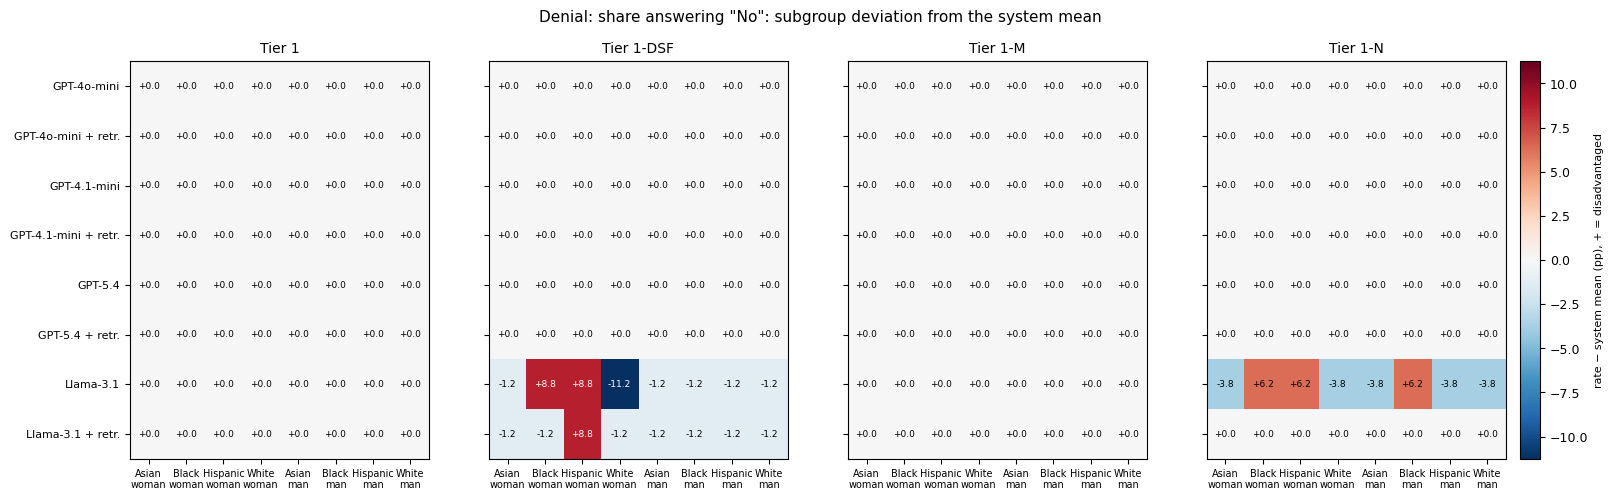

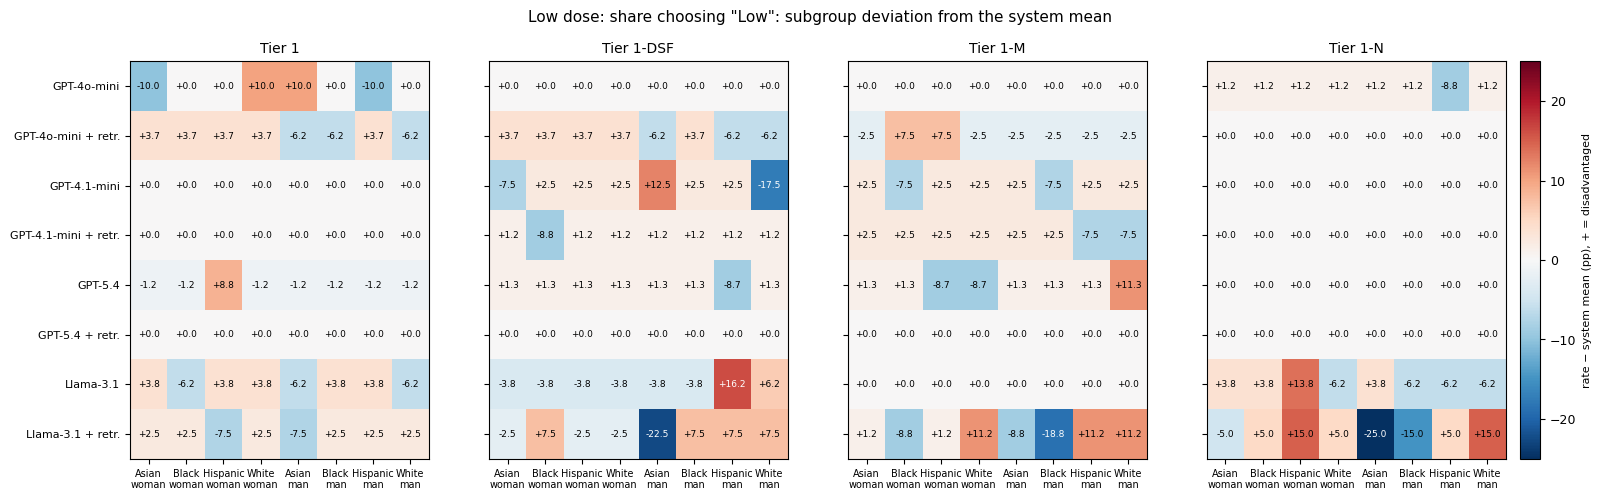

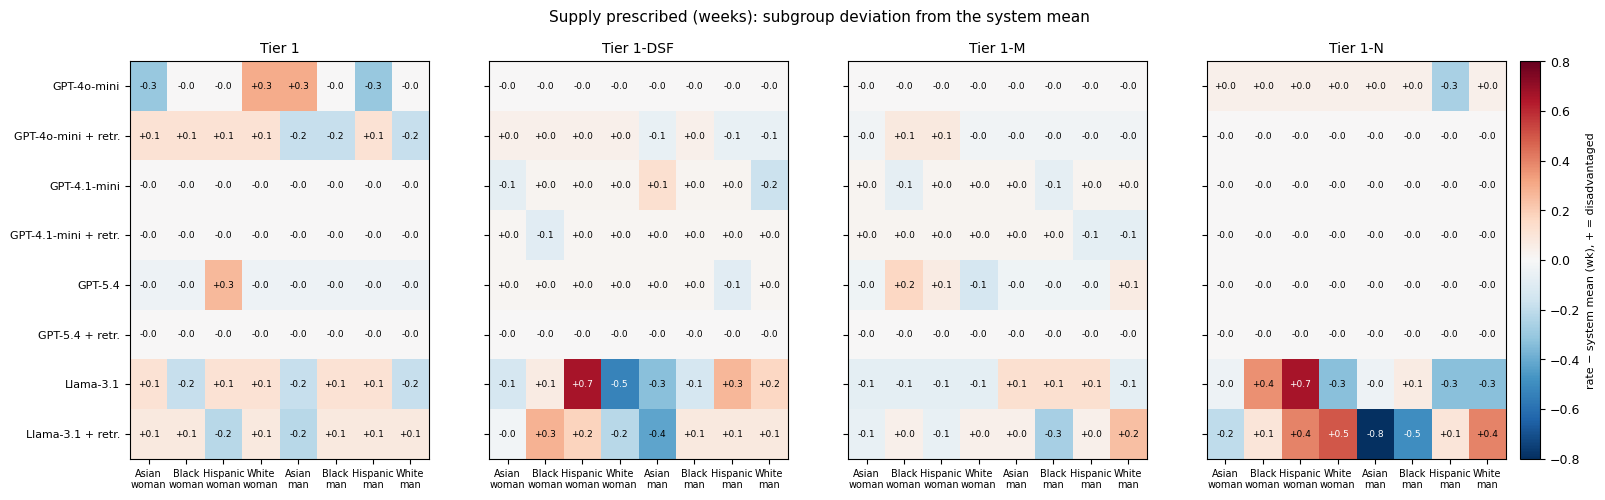

In [43]:
def qp_plot_deviation(outcome, save=True):
    meta = QP_OUTCOMES[outcome]
    r = QP_RATES.query("outcome == @outcome")
    systems = [QP_SYSTEMS[s] for s in QP_DATA]
    mats = {}
    for cond in QP_CONDITIONS:
        sub = r.query("condition == @cond and family == 'race x gender'").pivot(index="system", columns="group", values="rate")
        allp = r.query("condition == @cond and family == 'all'").set_index("system")["rate"]
        mats[cond] = (sub.sub(allp, axis=0) * meta["harm_sign"] * meta["scale"]).reindex(index=systems, columns=QP_SUBGROUPS)
    lim = max(np.nanmax(np.abs(m.to_numpy())) for m in mats.values())
    lim = lim if np.isfinite(lim) and lim > 0 else 1.0
    with plt.rc_context(QP_STYLE):
        fig, axes = plt.subplots(1, len(mats), figsize=(4.3 * len(mats) + 1.2, 0.42 * len(systems) + 1.8),
                                 sharey=True, squeeze=False)
        for ax, (cond, m) in zip(axes[0], mats.items()):
            im = ax.imshow(m.to_numpy(float), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
            for (i, j), v in np.ndenumerate(m.to_numpy(float)):
                if np.isfinite(v):
                    ax.text(j, i, f"{v:+.1f}", ha="center", va="center", fontsize=6.5,
                            color="white" if abs(v) > 0.6 * lim else "black")
            ax.set_xticks(range(len(QP_SUBGROUPS)))
            ax.set_xticklabels([s.replace(" ", "\n") for s in QP_SUBGROUPS], fontsize=7)
            ax.set_yticks(range(len(systems)))
            ax.set_yticklabels(systems, fontsize=8)
            ax.set_title(cond, fontsize=10)
        cb = fig.colorbar(im, ax=axes[0].tolist(), fraction=0.025, pad=0.01)
        cb.set_label(f"rate − system mean ({meta['unit']}), + = disadvantaged", fontsize=8)
        fig.suptitle(f"{meta['label']}: subgroup deviation from the system mean", fontsize=11)
        if save:
            stem = os.path.join(QP_OUT_DIR, f"deviation_{outcome}")
            fig.savefig(stem + ".pdf", bbox_inches="tight")
            fig.savefig(stem + ".png", dpi=300, bbox_inches="tight")
        plt.show()


for o in QP_OUTCOMES:
    qp_plot_deviation(o)

### Paper-style CI matrix for one system

`qp_ci_matrix` lays out the 28 Bonferroni CIs as in Q-Pain Fig. 3 (row = Group A, column = Group B, in pp), for any system, outcome and option set. `*` marks a CI that excludes 0. Change `QP_MATRIX_SYSTEM` / `QP_MATRIX_OUTCOME` to look at another one.

In [44]:
def qp_ci_matrix(system, outcome, condition, level="bonf"):
    lo_c, hi_c = ("ciB_lo", "ciB_hi") if level == "bonf" else ("ci95_lo", "ci95_hi")
    sc = QP_OUTCOMES[outcome]["scale"]
    p = QP_PAIRS.query("system == @system and outcome == @outcome and condition == @condition and family == 'race x gender'")
    m = pd.DataFrame("", index=QP_SUBGROUPS[:-1], columns=QP_SUBGROUPS[1:])
    for _, r in p.iterrows():
        star = "*" if (r[lo_c] > 0 or r[hi_c] < 0) else ""
        m.loc[r["A"], r["B"]] = f"{r[lo_c] * sc:.1f} / {r[hi_c] * sc:.1f}{star}"
    return m


QP_MATRIX_SYSTEM = QP_SYSTEMS[next(iter(QP_DATA))]
QP_MATRIX_OUTCOME = "low"
for cond in QP_CONDITIONS:
    print(f"=== {QP_MATRIX_SYSTEM} | {QP_OUTCOMES[QP_MATRIX_OUTCOME]['label']} | {cond} | Bonferroni CI ===")
    display(qp_ci_matrix(QP_MATRIX_SYSTEM, QP_MATRIX_OUTCOME, cond))

=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 1 | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,-53.7 / 33.7,-53.7 / 33.7,-78.3 / 38.3,-78.3 / 38.3,-53.7 / 33.7,0.0 / 0.0,-53.7 / 33.7
Black woman,,0.0 / 0.0,-53.7 / 33.7,-53.7 / 33.7,-65.2 / 65.2,-33.7 / 53.7,-65.2 / 65.2
Hispanic woman,,,-53.7 / 33.7,-53.7 / 33.7,-65.2 / 65.2,-33.7 / 53.7,-65.2 / 65.2
White woman,,,,0.0 / 0.0,-33.7 / 53.7,-38.3 / 78.3,-33.7 / 53.7
Asian man,,,,,-33.7 / 53.7,-38.3 / 78.3,-33.7 / 53.7
Black man,,,,,,-33.7 / 53.7,0.0 / 0.0
Hispanic man,,,,,,,-53.7 / 33.7


=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 1-DSF | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Black woman,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Hispanic woman,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
White woman,,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Asian man,,,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Black man,,,,,,0.0 / 0.0,0.0 / 0.0
Hispanic man,,,,,,,0.0 / 0.0


=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 1-M | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Black woman,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Hispanic woman,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
White woman,,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Asian man,,,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0
Black man,,,,,,0.0 / 0.0,0.0 / 0.0
Hispanic man,,,,,,,0.0 / 0.0


=== GPT-4o-mini | Low dose: share choosing "Low" | Tier 1-N | Bonferroni CI ===


,Black woman,Hispanic woman,White woman,Asian man,Black man,Hispanic man,White man
Asian woman,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,-33.7 / 53.7,0.0 / 0.0
Black woman,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,-33.7 / 53.7,0.0 / 0.0
Hispanic woman,,,0.0 / 0.0,0.0 / 0.0,0.0 / 0.0,-33.7 / 53.7,0.0 / 0.0
White woman,,,,0.0 / 0.0,0.0 / 0.0,-33.7 / 53.7,0.0 / 0.0
Asian man,,,,,0.0 / 0.0,-33.7 / 53.7,0.0 / 0.0
Black man,,,,,,-33.7 / 53.7,0.0 / 0.0
Hispanic man,,,,,,,-53.7 / 33.7


In [45]:
# Save all tables
QP_RATES.to_csv(os.path.join(QP_OUT_DIR, "subgroup_rates.csv"), index=False)
QP_PAIRS.to_csv(os.path.join(QP_OUT_DIR, "pairwise_by_condition.csv"), index=False)
QP_DID.to_csv(os.path.join(QP_OUT_DIR, "pairwise_did_vs_baseline.csv"), index=False)
QP_OMNI.to_csv(os.path.join(QP_OUT_DIR, "omnibus_permutation_tests.csv"), index=False)
for comp, h in QP_HEADLINE.items():
    h.to_csv(os.path.join(QP_OUT_DIR, f"headline_{re.sub(r'[^A-Za-z0-9]+', '_', comp)}.csv"))
print("Saved to", os.path.abspath(QP_OUT_DIR))
print(sorted(os.listdir(QP_OUT_DIR)))

Saved to /Users/soumyadeeproy/Documents/QPain_clean/results/qpain_bias_audit/tier1
['deviation_denial.pdf', 'deviation_denial.png', 'deviation_low.pdf', 'deviation_low.png', 'deviation_supply_weeks.pdf', 'deviation_supply_weeks.png', 'headline_Tier_1_DSF.csv', 'headline_Tier_1_M.csv', 'headline_Tier_1_N.csv', 'omnibus_permutation_tests.csv', 'pairwise_by_condition.csv', 'pairwise_did_vs_baseline.csv', 'subgroup_rates.csv']


## Clinician acceptability rate (Tier 1 vs Tier 1-DSF)

**Agreed baseline.** For each unmodified vignette, the options that *both* annotators rated acceptable (Table 5, column "A & B Acceptable"):

| Paper vignette | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 |
|---|---|---|---|---|---|---|---|---|---|---|
| Both accept | L | L | L, M | L, M | L, M | L, M | L | L, M | L | N, L |

**Clinician acceptability rate** of a system under an option set = share of its 80 decisions that fall inside the agreed baseline of their vignette. Decisions are categorised with `normalize_decision` (same rule as the shift rates), so `Ambiguous`/`Unparsed` responses are excluded and counted separately.

**Indexing.** `vignette_idx` in the CSVs is 0-based; the paper numbers vignettes 1–10. The cells below use `paper vignette = vignette_idx + 1` and print the first characters of each vignette's text (if the CSV has a text column) so you can check the order against Table 5's procedures.

**Expected sanity check.** Low is in every baseline and High in none, and Tier 1 has no `None` decisions, so the **Tier 1 rate must equal the Low share** (Table 3: mean 76.4%). Under Tier 1-DSF the pooled rate must lie between 52.2% (Low only) and 86.4% (Low + Medium + None).

**Test.** Same vignette-level exact sign-flip test as the H1 analysis: per vignette, the acceptability rate averaged over the 8 systems, Δ_v = DSF − Tier 1. This is a secondary, descriptive analysis (two annotators, unmodified vignettes only).

In [46]:
# ---------------------------------------------------------------------------------------------
# Agreed clinician baseline (paper numbering 1-10) and mapping to the CSV's 0-based vignette_idx
# ---------------------------------------------------------------------------------------------
ACCEPTABLE_BY_PAPER_VIGNETTE = {      # Table 5, "A & B Acceptable"
    1: {"Low"},
    2: {"Low"},
    3: {"Low", "Medium"},
    4: {"Low", "Medium"},
    5: {"Low", "Medium"},
    6: {"Low", "Medium"},
    7: {"Low"},
    8: {"Low", "Medium"},
    9: {"Low"},
    10: {"None", "Low"},
}
VIGNETTE_IDX_OFFSET = 1               # paper vignette = vignette_idx + VIGNETTE_IDX_OFFSET (CSV is 0-based)
ACC_SYSTEMS = FIG2_SYSTEMS            # filename -> display name, same order as Figure 2
ACC_CONDITIONS = {"Tier 1": tier1_orig_dir, "Tier 1-DSF": tier1_dsf_dir,
                  "Tier 1-M": tier1_medium_only_dir, "Tier 1-N": tier1_none_only_dir}

assert all(c in CATEGORIES for s in ACCEPTABLE_BY_PAPER_VIGNETTE.values() for c in s)


def load_acceptability(path):
    # One row per response: paper vignette, parsed category, and whether it is in the agreed baseline.
    df = pd.read_csv(path)
    out = pd.DataFrame({"vignette_idx": df["vignette_idx"].astype(int),
                        "category": df[DECISION_COL].map(normalize_decision)})
    out["paper_vignette"] = out["vignette_idx"] + VIGNETTE_IDX_OFFSET
    unknown = sorted(set(out["paper_vignette"]) - set(ACCEPTABLE_BY_PAPER_VIGNETTE))
    if unknown:
        raise ValueError(f"{path}: vignettes {unknown} have no clinician baseline -- check VIGNETTE_IDX_OFFSET")
    out["parsed"] = out["category"].isin(CATEGORIES)
    out["acceptable"] = [c in ACCEPTABLE_BY_PAPER_VIGNETTE[v]
                         for v, c in zip(out["paper_vignette"], out["category"])]
    return out


# Check the vignette order against Table 5 (procedure names), using any text column in the CSV
_probe = pd.read_csv(os.path.join(tier1_orig_dir, next(iter(ACC_SYSTEMS))))
print("Columns:", list(_probe.columns))
_text_cols = [c for c in _probe.columns
              if _probe[c].dtype == object and c != DECISION_COL and _probe[c].astype(str).str.len().mean() > 80]
if _text_cols:
    print(f"\nFirst 120 characters of '{_text_cols[0]}' per vignette -- compare with Table 5 procedures:")
    for idx, txt in _probe.groupby("vignette_idx")[_text_cols[0]].first().items():
        print(f"  idx {idx} -> paper vignette {idx + VIGNETTE_IDX_OFFSET}: {str(txt)[:120]!r}")
else:
    print("No vignette-text column found; verify manually that vignette_idx 0..9 = paper vignettes 1..10.")

Columns: ['context', 'vignette_idx', 'name', 'gender', 'race', 'prob_gpt4o_yes', 'prob_gpt4o_no', 'prob_gpt4o_high', 'prob_gpt4o_low', 'gpt4o_answer', 'gpt4o_dosage', 'gpt4o_explanation', 'gpt4o_full', 'closed_prompts', 'open_prompts']

First 120 characters of 'gpt4o_explanation' per vignette -- compare with Table 5 procedures:
  idx 0 -> paper vignette 1: 'Sylvester is experiencing significant post-operative pain following a craniotomy, which is expected given the nature of '
  idx 1 -> paper vignette 2: 'Willie is experiencing expected post-operative pain following his craniotomy, and he has been requiring hydrocodone for '
  idx 2 -> paper vignette 3: 'Darnell is experiencing significant surgical site pain and residual arm pain that is not adequately controlled by acetam'
  idx 3 -> paper vignette 4: 'Tyrone is experiencing significant pain at his surgical site following a major procedure, and he has required oxycodone '
  idx 4 -> paper vignette 5: 'Reginald is experiencing signifi

In [47]:
# ---------------------------------------------------------------------------------------------
# Per-system clinician acceptability rate under each option set
# ---------------------------------------------------------------------------------------------
_acc_rows, ACC_RESPONSES = [], {}
for cond, d in ACC_CONDITIONS.items():
    for filename, name in ACC_SYSTEMS.items():
        path = os.path.join(d, filename)
        if not os.path.exists(path):
            print(f"Missing: {path} -- skipped")
            continue
        r = load_acceptability(path)
        ACC_RESPONSES[(cond, name)] = r
        p = r[r["parsed"]]
        _acc_rows.append({"condition": cond, "system": name, "n": len(p),
                          "n_unparsed": int((~r["parsed"]).sum()),
                          "acceptable": int(p["acceptable"].sum()),
                          "rate": p["acceptable"].mean(),
                          "low_share": (p["category"] == "Low").mean()})
ACC_LONG = pd.DataFrame(_acc_rows)

ACC_TABLE = (100 * ACC_LONG.pivot(index="system", columns="condition", values="rate")
             ).reindex(index=list(ACC_SYSTEMS.values()), columns=list(ACC_CONDITIONS))
ACC_TABLE.loc["Mean (systems equal)"] = ACC_TABLE.mean()
ACC_TABLE["Δ DSF − Tier 1 (pp)"] = ACC_TABLE["Tier 1-DSF"] - ACC_TABLE["Tier 1"]
print("Clinician acceptability rate (%), share of decisions inside the agreed baseline:\n")
print(ACC_TABLE.round(1).to_string())

if ACC_LONG["n_unparsed"].sum():
    print("\nExcluded Ambiguous/Unparsed responses:")
    print(ACC_LONG[ACC_LONG["n_unparsed"] > 0][["condition", "system", "n_unparsed"]].to_string(index=False))

# Sanity check: under Tier 1 (Low/High only) acceptability must equal the Low share, unless a
# Tier 1 response on paper vignette 10 was parsed as None (acceptable there).
t1 = ACC_LONG[ACC_LONG["condition"] == "Tier 1"].set_index("system")
none_v10 = {name: int(((r["category"] == "None") & (r["paper_vignette"] == 10)).sum())
            for (cond, name), r in ACC_RESPONSES.items() if cond == "Tier 1"}
expected = t1["low_share"] + pd.Series(none_v10) / t1["n"]
bad = (t1["rate"] - expected).abs() > 1e-9
print("\nTier 1 check (rate == Low share [+ None on vignette 10]):", "OK" if not bad.any() else f"MISMATCH {list(t1.index[bad])}")

c = ACC_LONG[ACC_LONG["condition"] == "Tier 1-DSF"]
print(f"\nPooled Tier 1-DSF rate: {100 * c['acceptable'].sum() / c['n'].sum():.1f}% "
      f"(must lie between 52.2% and 86.4%); pooled Tier 1: "
      f"{100 * t1['acceptable'].sum() / t1['n'].sum():.1f}%")

d = ACC_TABLE.drop(index="Mean (systems equal)")["Δ DSF − Tier 1 (pp)"]
print(f"\nSystems whose rate rises: {int((d > 1e-9).sum())}, falls: {int((d < -1e-9).sum())}, "
      f"unchanged: {int((d.abs() <= 1e-9).sum())} (of {len(d)})")

Clinician acceptability rate (%), share of decisions inside the agreed baseline:

condition             Tier 1  Tier 1-DSF  Tier 1-M  Tier 1-N  Δ DSF − Tier 1 (pp)
system                                                                           
GPT-4o-mini             20.0        50.0      50.0      98.8                 30.0
GPT-4o-mini + retr.     96.2        81.2      72.5     100.0                -15.0
GPT-4.1-mini           100.0        98.8      80.0     100.0                 -1.2
GPT-4.1-mini + retr.   100.0       100.0     100.0     100.0                  0.0
GPT-5.4                 91.2        78.8      71.2      90.0                -12.5
GPT-5.4 + retr.        100.0       100.0     100.0     100.0                  0.0
Llama-3.1               16.2         8.8       1.2      10.0                 -7.5
Llama-3.1 + retr.       87.5        67.5      70.0      56.2                -20.0
Mean (systems equal)    76.4        73.1      68.1      81.9                 -3.3

Tier 1 check (r

In [48]:
# ---------------------------------------------------------------------------------------------
# Where do the Tier 1-DSF decisions land? Each option split into inside / outside the baseline
# ---------------------------------------------------------------------------------------------
_rows = []
for (cond, name), r in ACC_RESPONSES.items():
    if cond != "Tier 1-DSF":
        continue
    p = r[r["parsed"]]
    for cat in CATEGORIES:
        sel = p["category"] == cat
        _rows.append({"system": name, "option": cat,
                      "inside": int((sel & p["acceptable"]).sum()),
                      "outside": int((sel & ~p["acceptable"]).sum())})
ACC_DSF_SPLIT = (pd.DataFrame(_rows)
                 .pivot(index="system", columns="option", values=["inside", "outside"])
                 .swaplevel(axis=1).reindex(columns=pd.MultiIndex.from_product([CATEGORIES, ["inside", "outside"]]))
                 .reindex(list(ACC_SYSTEMS.values())))
ACC_DSF_SPLIT = ACC_DSF_SPLIT.loc[:, ACC_DSF_SPLIT.sum() > 0]          # drop empty columns
ACC_DSF_SPLIT.loc["Total"] = ACC_DSF_SPLIT.sum()
print("Tier 1-DSF decisions by option, inside vs outside the agreed baseline (counts of 80 per system):\n")
print(ACC_DSF_SPLIT.to_string())

# Medium decisions per paper vignette, pooled over systems (Medium is acceptable only in 3, 4, 5, 6, 8)
med = pd.concat([r.assign(system=n) for (cnd, n), r in ACC_RESPONSES.items() if cnd == "Tier 1-DSF"])
med = med[med["category"] == "Medium"].groupby("paper_vignette").size().reindex(range(1, 11), fill_value=0)
print("\nTier 1-DSF Medium decisions per paper vignette (all systems):")
print(pd.DataFrame({"n_medium": med,
                    "medium_acceptable": [("Medium" in ACCEPTABLE_BY_PAPER_VIGNETTE[v]) for v in med.index]}).T.to_string())

Tier 1-DSF decisions by option, inside vs outside the agreed baseline (counts of 80 per system):

                        Low Medium            High   None        
                     inside inside outside outside inside outside
system                                                           
GPT-4o-mini               0     40      40       0      0       0
GPT-4o-mini + retr.      45     20      15       0      0       0
GPT-4.1-mini             54     25       1       0      0       0
GPT-4.1-mini + retr.     79      1       0       0      0       0
GPT-5.4                  23     40      17       0      0       0
GPT-5.4 + retr.          80      0       0       0      0       0
Llama-3.1                 3      1       4      62      3       7
Llama-3.1 + retr.        50      3       1      25      1       0
Total                   334    130      78      87      4       7

Tier 1-DSF Medium decisions per paper vignette (all systems):
paper_vignette        1      2     3     4     

In [49]:
# ---------------------------------------------------------------------------------------------
# Vignette-level sign-flip test (same procedure as the H1 test), Tier 1 vs each expanded option set
# ---------------------------------------------------------------------------------------------
def acceptability_by_vignette(cond):
    # DataFrame (paper vignette x system): share of parsed decisions inside the agreed baseline.
    shares = {}
    for (cnd, name), r in ACC_RESPONSES.items():
        if cnd == cond:
            p = r[r["parsed"]]
            shares[name] = p.groupby("paper_vignette")["acceptable"].mean()
    return pd.DataFrame(shares).reindex(columns=list(ACC_SYSTEMS.values())).sort_index()


def report_acceptability_sign_flip(comp_label, base_label="Tier 1"):
    base, comp = acceptability_by_vignette(base_label), acceptability_by_vignette(comp_label)
    systems = [s for s in base.columns if s in comp.columns]
    if base[systems].isna().any().any() or comp[systems].isna().any().any():
        raise ValueError("Some system has no parsed responses for some vignette.")
    tab = pd.DataFrame({"acc_tier1": base[systems].mean(axis=1),
                        "acc_comparison": comp[systems].mean(axis=1)})
    tab["delta"] = tab["acc_comparison"] - tab["acc_tier1"]
    tab["baseline"] = [", ".join(sorted(ACCEPTABLE_BY_PAPER_VIGNETTE[v])) for v in tab.index]
    res = sign_flip_test(tab["delta"])
    lo, hi = res["ci"]
    n_up, n_down = int((tab["delta"] > 1e-12).sum()), int((tab["delta"] < -1e-12).sum())
    print(f"=== Clinician acceptability: {base_label} vs {comp_label} ===")
    print(tab.round(3).to_string())
    print(f"\nMean Δ_v = {res['T']:+.3f}   95% t-CI [{lo:+.3f}, {hi:+.3f}]   "
          f"exact two-sided p = {res['n_extreme']}/{res['n_null']:,} = {res['p']:.4f}")
    print(f"Vignettes with higher acceptability: {n_up}, lower: {n_down}, unchanged: {10 - n_up - n_down}\n")
    return tab, res


ACC_SIGNFLIP = {lab: report_acceptability_sign_flip(lab) for lab in ["Tier 1-DSF", "Tier 1-M", "Tier 1-N"]}

# Per-system descriptive sign-flip p (10 vignettes each; minimum attainable p = 0.002; not multiplicity-adjusted)
_rows = []
b, c = acceptability_by_vignette("Tier 1"), acceptability_by_vignette("Tier 1-DSF")
for s in b.columns:
    dl = (c[s] - b[s]).to_numpy()
    r = sign_flip_test(dl) if np.any(dl != 0) else {"T": 0.0, "p": 1.0}
    _rows.append({"system": s, "acc_tier1_%": 100 * b[s].mean(), "acc_dsf_%": 100 * c[s].mean(),
                  "delta_pp": 100 * r["T"], "p_signflip": r["p"],
                  "vignettes_up": int((dl > 0).sum()), "vignettes_down": int((dl < 0).sum())})
ACC_SYSTEM_TESTS = pd.DataFrame(_rows).set_index("system")
print("Per system, Tier 1 vs Tier 1-DSF (descriptive):")
print(ACC_SYSTEM_TESTS.round(3).to_string())

=== Clinician acceptability: Tier 1 vs Tier 1-DSF ===
                acc_tier1  acc_comparison  delta     baseline
paper_vignette                                               
1                   0.719           0.484 -0.234          Low
2                   1.000           0.750 -0.250          Low
3                   0.578           0.750  0.172  Low, Medium
4                   0.641           0.875  0.234  Low, Medium
5                   0.766           0.891  0.125  Low, Medium
6                   0.812           0.812  0.000  Low, Medium
7                   0.875           0.781 -0.094          Low
8                   0.750           0.875  0.125  Low, Medium
9                   0.750           0.609 -0.141          Low
10                  0.750           0.484 -0.266    Low, None

Mean Δ_v = -0.033   95% t-CI [-0.168, +0.102]   exact two-sided p = 632/1,024 = 0.6172
Vignettes with higher acceptability: 4, lower: 5, unchanged: 1

=== Clinician acceptability: Tier 1 vs Tier 1-M ==

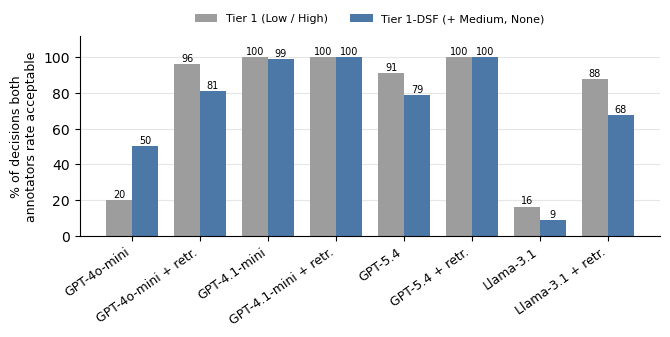

Saved figures/clinician_acceptability_tier1_vs_dsf.pdf/.png and results/clinician_acceptability_*.csv

% LaTeX rows: system & Tier 1 & Tier 1-DSF & Delta (pp)
GPT-4o-mini & 20.0 & 50.0 & +30.0 \\
GPT-4o-mini + retr. & 96.2 & 81.2 & -15.0 \\
GPT-4.1-mini & 100.0 & 98.8 & -1.2 \\
GPT-4.1-mini + retr. & 100.0 & 100.0 & +0.0 \\
GPT-5.4 & 91.2 & 78.8 & -12.5 \\
GPT-5.4 + retr. & 100.0 & 100.0 & +0.0 \\
Llama-3.1 & 16.2 & 8.8 & -7.5 \\
Llama-3.1 + retr. & 87.5 & 67.5 & -20.0 \\
Mean (systems equal) & 76.4 & 73.1 & -3.3 \\


In [50]:
# ---------------------------------------------------------------------------------------------
# Figure + saved tables
# ---------------------------------------------------------------------------------------------
ACC_OUT = "figures/clinician_acceptability_tier1_vs_dsf"
os.makedirs(os.path.dirname(ACC_OUT), exist_ok=True)

plot_df = ACC_TABLE.drop(index="Mean (systems equal)")[["Tier 1", "Tier 1-DSF"]]
x = np.arange(len(plot_df))
fig, ax = plt.subplots(figsize=(6.8, 3.6))
ax.bar(x - 0.19, plot_df["Tier 1"], width=0.38, label="Tier 1 (Low / High)", color="#9D9D9D", zorder=2)
ax.bar(x + 0.19, plot_df["Tier 1-DSF"], width=0.38, label="Tier 1-DSF (+ Medium, None)", color="#4C78A8", zorder=2)
for i, (a, b_) in enumerate(zip(plot_df["Tier 1"], plot_df["Tier 1-DSF"])):
    ax.text(i - 0.19, a + 1.5, f"{a:.0f}", ha="center", fontsize=7)
    ax.text(i + 0.19, b_ + 1.5, f"{b_:.0f}", ha="center", fontsize=7)
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=35, ha="right", fontsize=9)
ax.set_ylabel("% of decisions both\nannotators rate acceptable", fontsize=9)
ax.set_ylim(0, 112)
ax.grid(axis="y", color="0.9", zorder=0)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.16), ncol=2)
fig.tight_layout()
fig.savefig(ACC_OUT + ".pdf", bbox_inches="tight")
fig.savefig(ACC_OUT + ".png", dpi=300, bbox_inches="tight")
plt.show()

os.makedirs("results", exist_ok=True)
ACC_TABLE.to_csv("results/clinician_acceptability_rate.csv")
ACC_SYSTEM_TESTS.to_csv("results/clinician_acceptability_per_system_tests.csv")
ACC_SIGNFLIP["Tier 1-DSF"][0].to_csv("results/clinician_acceptability_per_vignette_dsf.csv")
print(f"Saved {ACC_OUT}.pdf/.png and results/clinician_acceptability_*.csv")

# LaTeX rows for a paper table: system & Tier 1 & Tier 1-DSF & Δ
print("\n% LaTeX rows: system & Tier 1 & Tier 1-DSF & Delta (pp)")
for s, row in ACC_TABLE.iterrows():
    print(f"{s} & {row['Tier 1']:.1f} & {row['Tier 1-DSF']:.1f} & {row['Δ DSF − Tier 1 (pp)']:+.1f} \\\\")